# Setting

In [224]:
import os
import glob
import pandas as pd
import numpy as np
import scipy
import matplotlib.pyplot as plt
import itertools
import math
from tqdm import tqdm

curfolder = os.getcwd()
print(curfolder)

mtfolder = curfolder + '/Output_TimeSeries/'
print(mtfolder)

processedfolder = curfolder + '/TS_processed/'
vidfolder = curfolder + '/Output_Videos/'

# get all the files in the folder
bodyfiles = glob.glob(mtfolder + '*body_world.csv')
handfiles = glob.glob(mtfolder + '*hands_world.csv')

print(bodyfiles)

vidfiles = glob.glob(vidfolder + '*.mp4')
#print(vidfiles)

e:\VICOM_SignGes_Trajectory
e:\VICOM_SignGes_Trajectory/Output_TimeSeries/
['e:\\VICOM_SignGes_Trajectory/Output_TimeSeries\\flipped_IP06_02_ABHOLEN.mp4_body_world.csv', 'e:\\VICOM_SignGes_Trajectory/Output_TimeSeries\\GP02_AFFE.mp4_body_world.csv', 'e:\\VICOM_SignGes_Trajectory/Output_TimeSeries\\flipped_IP06_02_ABLEHNEN.mp4_body_world.csv', 'e:\\VICOM_SignGes_Trajectory/Output_TimeSeries\\GP02_ANFANG.mp4_body_world.csv', 'e:\\VICOM_SignGes_Trajectory/Output_TimeSeries\\GP02_ANGELN.mp4_body_world.csv', 'e:\\VICOM_SignGes_Trajectory/Output_TimeSeries\\GP02_ATEM.mp4_body_world.csv', 'e:\\VICOM_SignGes_Trajectory/Output_TimeSeries\\GP02_BART.mp4_body_world.csv', 'e:\\VICOM_SignGes_Trajectory/Output_TimeSeries\\flipped_IP06_02_AFFE.mp4_body_world.csv', 'e:\\VICOM_SignGes_Trajectory/Output_TimeSeries\\GP02_BETEN.mp4_body_world.csv', 'e:\\VICOM_SignGes_Trajectory/Output_TimeSeries\\GP02_BRIEF.mp4_body_world.csv', 'e:\\VICOM_SignGes_Trajectory/Output_TimeSeries\\flipped_IP06_02_AKKORDEON.mp4

# First quality check (body)

In [225]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.animation import FuncAnimation
from IPython.display import Video

# Load CSV file
outputcsv = glob.glob(mtfolder + '*.csv')  # Ensure outtputf_ts is defined
files = [x for x in outputcsv if 'GtST' in x]
files = [x for x in files if 'body_world' in x]
fileexample = files[1]
MT_tracking = pd.read_csv(fileexample)

# Create a figure and axis
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection='3d')

# Define the number of frames
num_frames = len(MT_tracking)

# Define the scatter plot
scatter = ax.scatter([], [], [], marker='o')

# Update function for animation
def update(frame):
    ax.clear()
    ax.set_xlabel('X Label')
    ax.set_ylabel('Z Label')
    ax.set_zlabel('Y Label')
    ax.set_title('3D Animation')
    
    # Set the limits of the axes based on the maximum values
    ax.set_xlim3d(0, 1)
    ax.set_ylim3d(20, 0)
    ax.set_zlim3d(0, 1) #we need to flip the vertical
    
    # Plot the data for the current frame
    frame_data = MT_tracking.iloc[frame]
    frame_data_body = MT_tracking.iloc[frame]
    x = frame_data.filter(like='X_')
    x_body = frame_data_body.filter(like='X_')
    y = frame_data.filter(like='Z_')
    y_body = frame_data_body.filter(like='Z_')
    z = frame_data.filter(like='Y_')
    z_body = frame_data_body.filter(like='Y_')
    # create scatter that has body in blue, and hands in red
    #scatter = ax.scatter(x, y, z, color='blue')
    scatter = ax.scatter(x_body, y_body, z_body*-1, color='red')

    return scatter

# Create the animation
ani = FuncAnimation(fig, update, frames=num_frames, interval=1000/30)

# Close the figure to prevent displaying the first frame
plt.close(fig)

# Save the animation as a video
ani.save('3D_animation_check.mp4', writer='ffmpeg')

# Display the animation
video_path = '3D_animation_check.mp4'
Video(video_path, embed=True, width=800)

# Preps for processing - one file example

## Clean the data

In [226]:

file = bodyfiles[0]
print(file)

e:\VICOM_SignGes_Trajectory/Output_TimeSeries\flipped_IP06_02_ABHOLEN.mp4_body_world.csv


In [245]:
problematic_vis = []


def longest_low_visibility_gap(vis_series, threshold=0.5):
    low_vis = (vis_series < threshold).astype(int)
    return max((sum(1 for _ in group) for val, group in itertools.groupby(low_vis) if val == 1), default=0)

def check_visibility_quality(df, keypoint, threshold=0.5, max_gap_len=15, max_low_ratio=0.3):
    vis_cols = [col for col in df.columns if keypoint in col and 'visibility' in col]
    if not vis_cols:
        return None  # No such keypoint found

    vis_series = df[vis_cols[0]]  # Only one column per keypoint
    low_ratio = (vis_series < threshold).mean()
    longest_gap = longest_low_visibility_gap(vis_series, threshold)

    is_flagged = (low_ratio > max_low_ratio) or (longest_gap > max_gap_len)
    return {
        "keypoint": keypoint,
        "low_ratio": low_ratio,
        "longest_gap": longest_gap,
        "flagged": is_flagged
    }

def check_for_visibility_string(df):
    for col in df.columns:
        if 'visibility' in col:
            return True
    return False

# get the last part of the path in sample
def clean_data(file, problems_list, no_vis):
    sample = pd.read_csv(file)
    fileID = os.path.basename(file)

    # replace _body.csv with ''
    fileID = fileID.replace('.mp4', '')
    fileID = fileID.replace('.csv', '')
    #print(fileID)

    # for this purpose we also don't need anything from hip lower
    todel = ['KNEE', 'ANKLE', 'FOOT']

    # get rid of all columns that contain the words from todel
    sample = sample.drop([col for col in sample.columns if any(x in col for x in todel)], axis=1)

    # add fileID column to the sample
    sample['fileID'] = fileID

    # Check each of the four keypoints separately
    keypoints = ['RIGHT_WRIST', 'LEFT_WRIST', 'RIGHT_ELBOW', 'LEFT_ELBOW']
    vis_results = {}

    # If there is no col for visibility, append it to no_vis list
    if not check_for_visibility_string(sample):
        no_vis.append(fileID)
        print(f"⚠️ No visibility column found for {fileID}.")
        return sample, problems_list, no_vis
        
    
    else:
        for kp in keypoints:
            result = check_visibility_quality(sample, keypoint=kp)
            if result:
                vis_results[kp] = result
                if result['flagged']:
                    if result['low_ratio'] > 0.3 and result['longest_gap'] > 25:
                        problems_list.append(fileID)
                        print(f"⚠️ {kp}: Low visibility detected — "
                            f"{result['low_ratio']*100:.1f}% low frames, "
                            f"max gap = {result['longest_gap']} frames.")

        # for body - lowbody columns
        lowbody = ['FOOT', 'HEEL', 'ANKLE', 'KEE']
        sample = sample.drop([col for col in sample.columns if any(x in col for x in lowbody)], axis=1)


    return sample, problems_list, no_vis

missing_vis = []
sample, problematic_vis, missing_vis = clean_data(file, problematic_vis, missing_vis)

# % low frames - The proportion of frames in the video/trial where the visibility value for a keypoint was below a certain threshold, typically indicating the keypoint was not reliably detected.



## Flip the Y axis vertical data

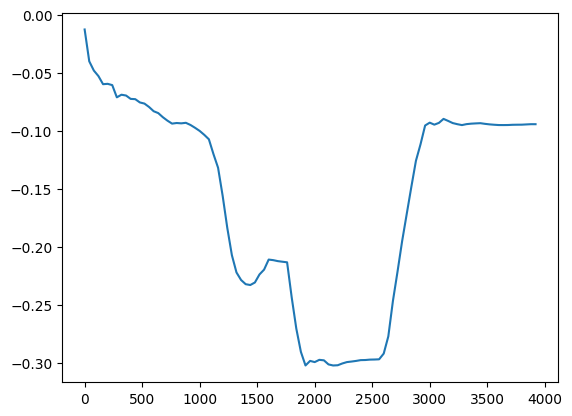

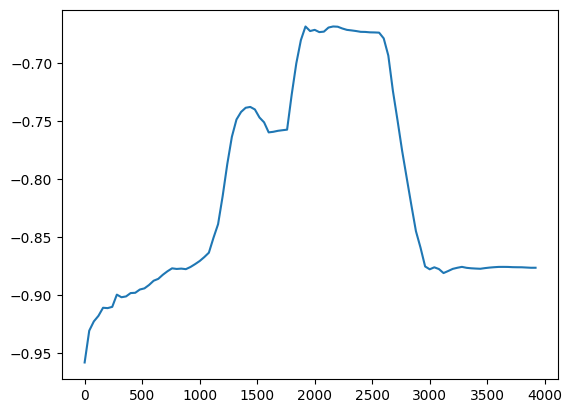

In [228]:
# plot left wrist, vertical (pre flipping)

plt.plot(sample['time'], sample['Y_LEFT_WRIST'])
plt.show()

# flip the y-axis data (code modified from envisionbox)
def flip_data(df):
    df = df.copy()  # avoid modifying original dataframe directly
    cols = [col for col in df.columns if 'Y_' in col]

    # Get max y-value from the first frame
    maxpoint = max(df.loc[0, cols])

    # Flip all Y_ columns across all rows
    for joint in cols:
        df.loc[:, joint] = maxpoint - df[joint] - 1

    return df

sample = flip_data(sample)

# plot left wrist, vertical (post flipping)

plt.plot(sample['time'], sample['Y_LEFT_WRIST'])
plt.show()

## Interpolate the data

In [229]:
# obtain column names
def interpolate(sample):
    cols = sample.columns
    #print(cols)

# put away time and fileID from cols
    cols = cols.drop(['time', 'fileID'])

# loop over the cols and interpolate missing data
    for col in cols:
        sample[col] = sample[col].interpolate(method='linear', x = sample['time'], limit=10)
    return cols, sample

cols, sample = interpolate(sample)

## Smooth the data

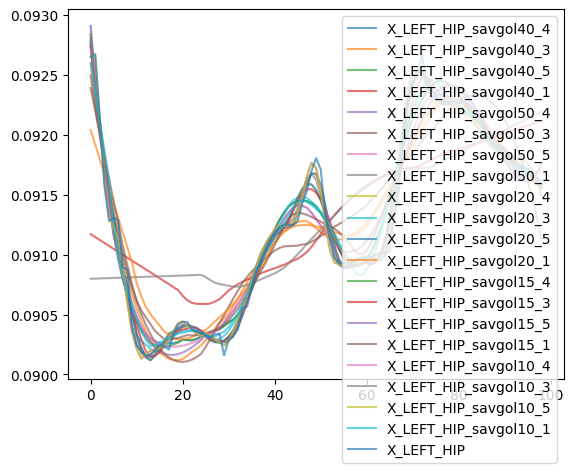

In [230]:
# test the different smoothing filter options - smoothing with savitzky-golay filter
x = 'X_LEFT_HIP'
z = 'Z_LEFT_HIP'
y = 'Y_LEFT_HIP'


# list possible window
window = [40, 50, 20, 15, 10]
# list possible orders
order = [4, 3, 5, 1]

# col of interest
samplecol = [y, z, x]

# iterate over handcols and apply all possible combinations of window and order, save it to new df
# prepare new df
df_smooth = pd.DataFrame()

for col in samplecol:
    for win in window:
        for ord in order:
            df_smooth[col + '_savgol' + str(win) + '_' + str(ord)] = scipy.signal.savgol_filter(sample[col], win, ord)


# make R_Hand_x from df_sample a list
LKnee_x = sample[x].tolist()
LKnee_y = sample[y].tolist()
LKnee_z = sample[z].tolist()


# load these values into df_smooth as a new column
df_smooth[x] = LKnee_x
df_smooth[y] = LKnee_y
df_smooth[z] = LKnee_z

#plot all R_Hand_x columns in one plot
colstoplot = [col for col in df_smooth.columns if x in col]
for col in colstoplot:
    plt.plot(df_smooth[col], label=col, alpha=0.65)
plt.legend()
plt.show()




We will use savgol 20,3 for upper body,

and 100, 1 for lower body (here only hip). We will not need it anyway (unless we want to normalize something), but it seems like there is lot of measurement error due to the sitting posture so strong filter is needed

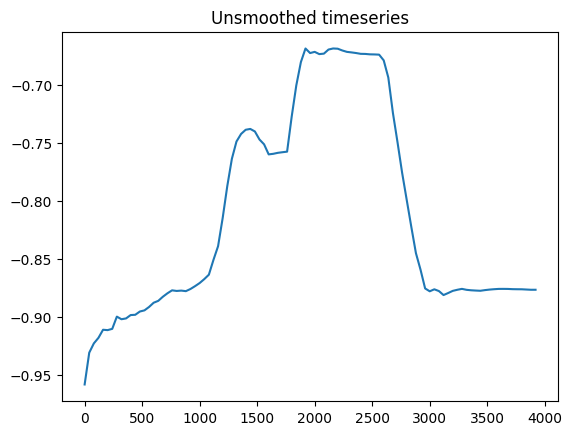

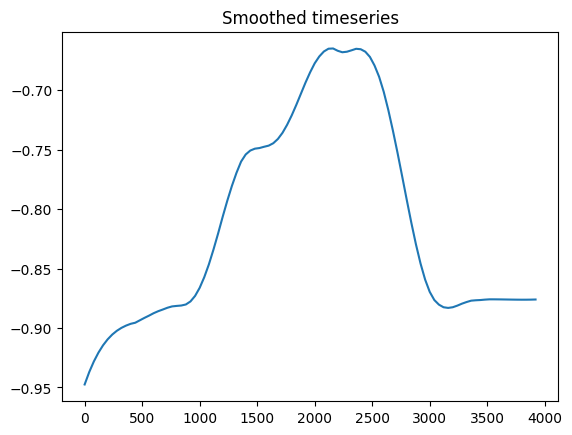

In [231]:
# obtain separate lists of the columns for the upper and lower body (face is included in upper body)

def smooth_data(sample):
    
    if 'body' in sample['fileID'][0]:

        cols_upperbody = ['X_NOSE', 'Y_NOSE', 'Z_NOSE', 'X_LEFT_EYE_INNER', 'Y_LEFT_EYE_INNER', 'Z_LEFT_EYE_INNER', 'X_LEFT_EYE', 'Y_LEFT_EYE', 'Z_LEFT_EYE', 'X_LEFT_EYE_OUTER', 'Y_LEFT_EYE_OUTER', 'Z_LEFT_EYE_OUTER', 'X_RIGHT_EYE_OUTER', 'Y_RIGHT_EYE_OUTER', 'Z_RIGHT_EYE_OUTER', 'X_RIGHT_EYE', 'Y_RIGHT_EYE', 'Z_RIGHT_EYE', 'X_RIGHT_EYE_OUTER.1', 'Y_RIGHT_EYE_OUTER.1', 'Z_RIGHT_EYE_OUTER.1', 'X_LEFT_EAR', 'Y_LEFT_EAR', 'Z_LEFT_EAR', 'X_RIGHT_EAR', 'Y_RIGHT_EAR', 'Z_RIGHT_EAR', 'X_MOUTH_LEFT', 'Y_MOUTH_LEFT', 'Z_MOUTH_LEFT', 'X_MOUTH_RIGHT', 'Y_MOUTH_RIGHT', 'Z_MOUTH_RIGHT', 'X_LEFT_SHOULDER', 'Y_LEFT_SHOULDER', 'Z_LEFT_SHOULDER', 'X_RIGHT_SHOULDER', 'Y_RIGHT_SHOULDER', 'Z_RIGHT_SHOULDER', 'X_LEFT_ELBOW', 'Y_LEFT_ELBOW', 'Z_LEFT_ELBOW', 'X_RIGHT_ELBOW', 'Y_RIGHT_ELBOW', 'Z_RIGHT_ELBOW', 'X_LEFT_WRIST', 'Y_LEFT_WRIST', 'Z_LEFT_WRIST', 'X_RIGHT_WRIST', 'Y_RIGHT_WRIST', 'Z_RIGHT_WRIST', 'X_LEFT_PINKY', 'Y_LEFT_PINKY', 'Z_LEFT_PINKY', 'X_RIGHT_PINKY', 'Y_RIGHT_PINKY', 'Z_RIGHT_PINKY', 'X_LEFT_INDEX', 'Y_LEFT_INDEX', 'Z_LEFT_INDEX', 'X_RIGHT_INDEX', 'Y_RIGHT_INDEX', 'Z_RIGHT_INDEX', 'X_LEFT_THUMB', 'Y_LEFT_THUMB', 'Z_LEFT_THUMB', 'X_RIGHT_THUMB', 'Y_RIGHT_THUMB']
        cols_lowerbody = ['X_LEFT_HIP', 'Y_LEFT_HIP', 'Z_LEFT_HIP', 'X_RIGHT_HIP', 'Y_RIGHT_HIP', 'Z_RIGHT_HIP']

        # smooth upperbody and face with savgol 20,4                            
        for col in cols_upperbody:
            sample[col] = scipy.signal.savgol_filter(sample[col], 21, 3)
        
        # smooth lowerbod with savgol 30,3
        for col in cols_lowerbody:  
            sample[col] = scipy.signal.savgol_filter(sample[col], 41, 1)

    elif 'hands' in sample['fileID'][0]:
        hand_cols = sample.columns
        # get rid of time and fileID
        hand_cols = hand_cols.drop(['time', 'fileID'])
        # smooth hand with savgol 20,4                                             
        for col in hand_cols:
            sample[col] = scipy.signal.savgol_filter(sample[col], 21, 4)
    
    return(sample)


plt.plot(sample['time'], sample['Y_LEFT_WRIST'])
plt.title('Unsmoothed timeseries')
plt.show()

sample = smooth_data(sample)

# plot the smoothed data
plt.plot(sample['time'], sample['Y_LEFT_WRIST'])
plt.title('Smoothed timeseries')
plt.show()

## Derive Speed and Smooth

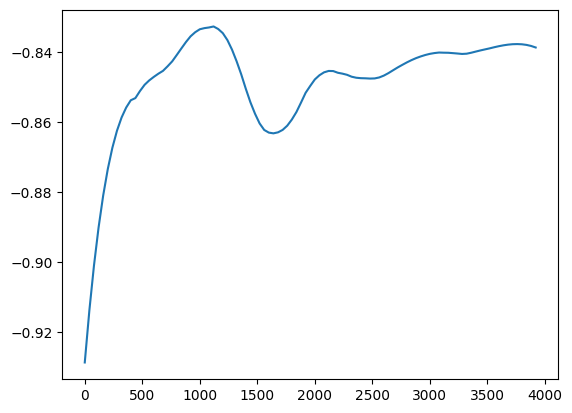

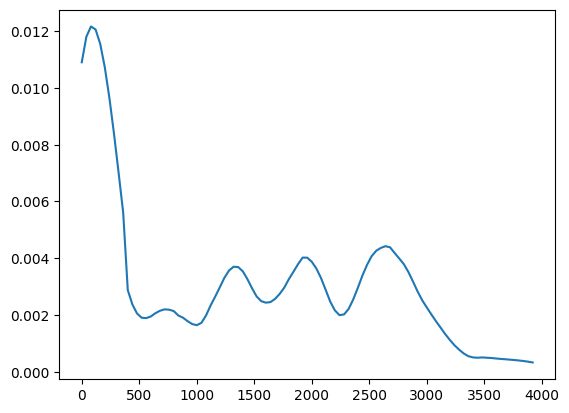

In [232]:
def derive_speed_smooth(cols, sample):
    speedcols = [col.replace('Y_', '').replace('X_', '').replace('Z_', '') for col in cols]
    speedcols = [col.replace('PINKF', 'PINKY_F').replace('INDEF', 'INDEX_F') for col in speedcols]
    speedcols = list(set(speedcols))  # keep only unique values

    # Get rid of all columns with visibility
    speedcols = [col for col in speedcols if 'visibility' not in col]

    speed_dict = {}

    for col in speedcols:
        try:
            x = sample['X_' + col].to_numpy()
            y = sample['Y_' + col].to_numpy()
            z = sample['Z_' + col].to_numpy()

            speed = np.insert(np.sqrt(np.diff(x)**2 + np.diff(y)**2 + np.diff(z)**2), 0, 0)
            speed = np.abs(speed)
            speed = scipy.signal.savgol_filter(speed, 20, 3)

            speed_dict[col + '_speed'] = speed
        except KeyError:
            print(f"Skipping {col}: missing data")
            continue

    # Add all new speed columns at once
    speed_df = pd.DataFrame(speed_dict)
    sample = pd.concat([sample.reset_index(drop=True), speed_df], axis=1)

    return sample


hand_cols = sample.columns
# get rid of time and fileID
hand_cols = hand_cols.drop(['time', 'fileID']) # 'fileID'
# get rid of visibility cols
hand_cols = hand_cols.drop([col for col in hand_cols if 'visibility' in col])

sample = derive_speed_smooth(hand_cols, sample)

# plot RIGHT_WRIST_speed
plt.plot(sample['time'], sample['Y_RIGHT_WRIST'])
plt.show()
plt.plot(sample['time'], sample['RIGHT_WRIST_speed'])
plt.show()

## Derive vertical velocity and smooth

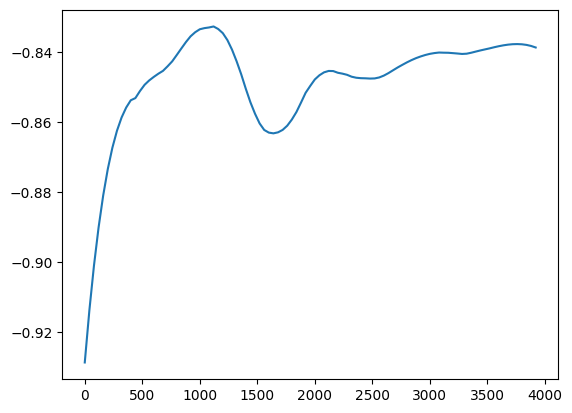

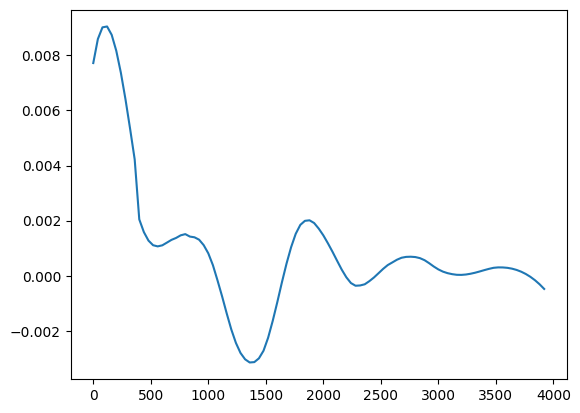

In [233]:
def derive_vertical_vel_smooth(sample):
    verticalcols = [col for col in sample.columns if 'Y_' in col and 'speed' not in col]
    new_vel_cols = {}

    for col in verticalcols:
        velocity = np.insert(np.diff(sample[col]), 0, 0)
        velocity = scipy.signal.savgol_filter(velocity, 20, 3)
        new_vel_cols[col + '_velocity'] = velocity

    sample = pd.concat([sample, pd.DataFrame(new_vel_cols, index=sample.index)], axis=1)
    return sample

sample = derive_vertical_vel_smooth(sample)

plt.plot(sample['time'], sample['Y_RIGHT_WRIST'])
plt.show()
plt.plot(sample['time'], sample['Y_RIGHT_WRIST_velocity'])
plt.show()

## Derive Acceleration and Smooth

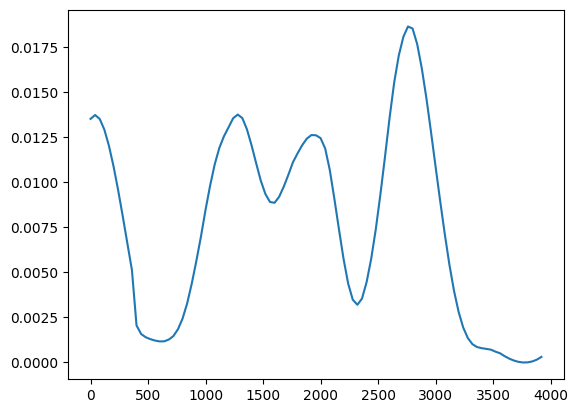

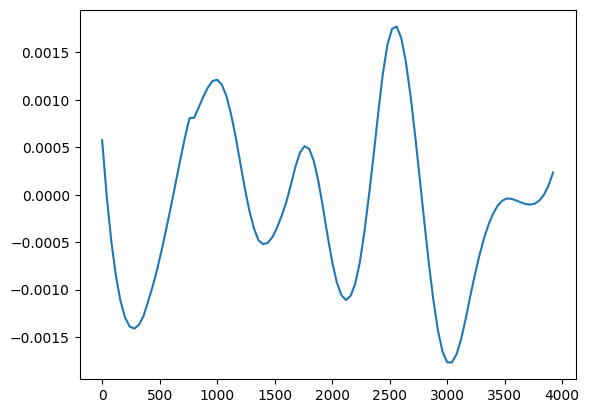

In [234]:
def derive_accel_smooth(speedcols, sample):

    new_accel_cols = {}

    for col in speedcols:
        newcolname = col.replace('speed', 'acceleration')
        accel = np.insert(np.diff(sample[col]), 0, 0)
        accel = scipy.signal.savgol_filter(accel, 20, 3)
        new_accel_cols[newcolname] = accel

    # Efficiently add all acceleration columns at once
    sample = pd.concat([sample, pd.DataFrame(new_accel_cols, index=sample.index)], axis=1)
    return sample

speedcols = [col for col in sample.columns if 'speed' in col]
sample = derive_accel_smooth(speedcols, sample)

plt.plot(sample['time'], sample['LEFT_WRIST_speed'])
plt.show()
plt.plot(sample['time'], sample['LEFT_WRIST_acceleration'])
plt.show()
    

## Derive Jerk and Smooth

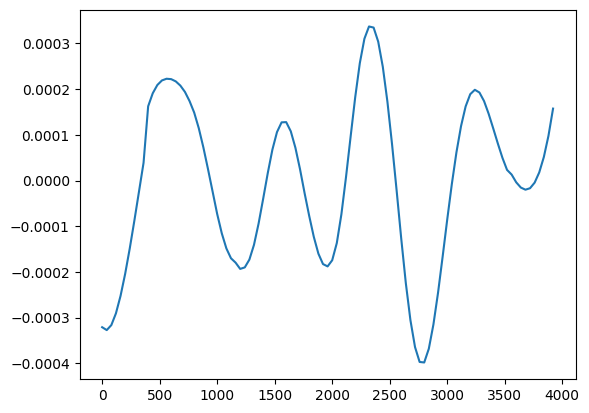

In [235]:
def derive_jerk_smooth(sample):

    # Find acceleration columns
    accols = [col for col in sample.columns if '_acceleration' in col]

    new_jerk_cols = {}

    for col in accols:
        newcolname = col.replace('acceleration', 'jerk')
        jerk = np.insert(np.diff(sample[col]), 0, 0)
        jerk = scipy.signal.savgol_filter(jerk, 20, 3)
        new_jerk_cols[newcolname] = jerk

    # Efficiently concatenate all new jerk columns
    sample = pd.concat([sample, pd.DataFrame(new_jerk_cols, index=sample.index)], axis=1)
    return sample

accols = [col for col in sample.columns if 'acceleration' in col]
sample = derive_jerk_smooth(sample)
plt.plot(sample['time'], sample['LEFT_WRIST_jerk'])
plt.show()


## Plotting all the derivations

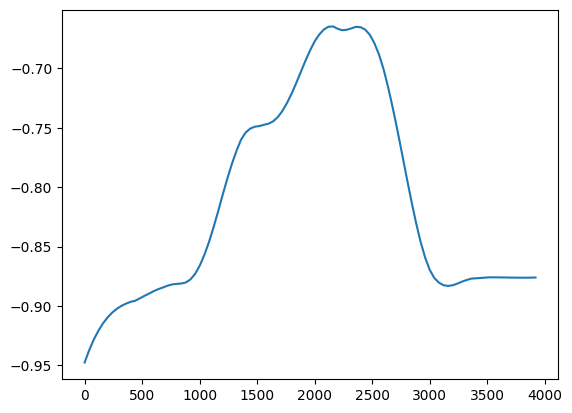

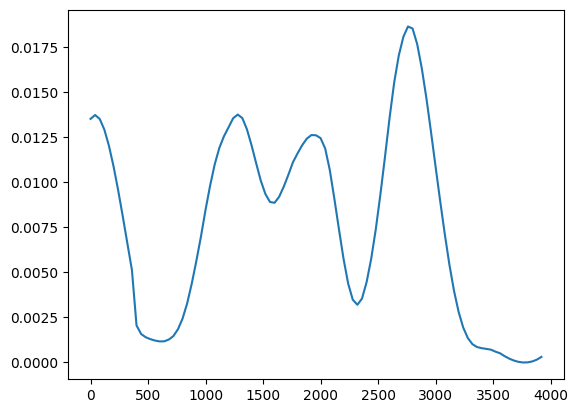

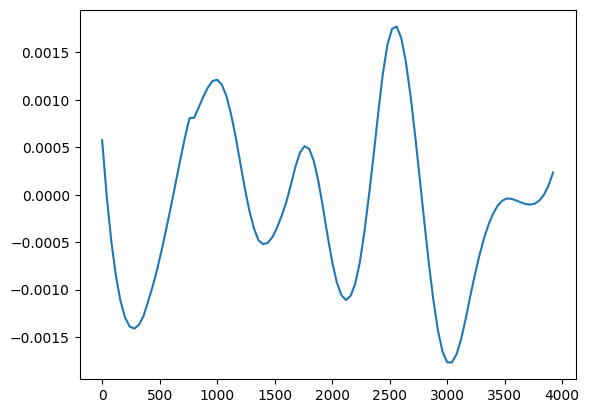

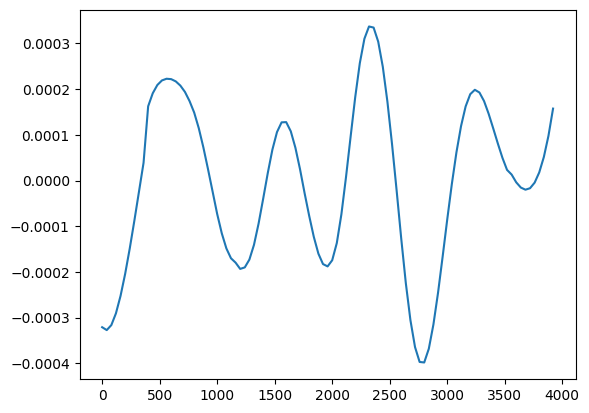

In [236]:

plt.plot(sample['time'], sample['Y_LEFT_WRIST'])
plt.show()
plt.plot(sample['time'], sample['LEFT_WRIST_speed'])
plt.show()
plt.plot(sample['time'], sample['LEFT_WRIST_acceleration'])
plt.show()
plt.plot(sample['time'], sample['LEFT_WRIST_jerk'])
plt.show()

## Computing angles

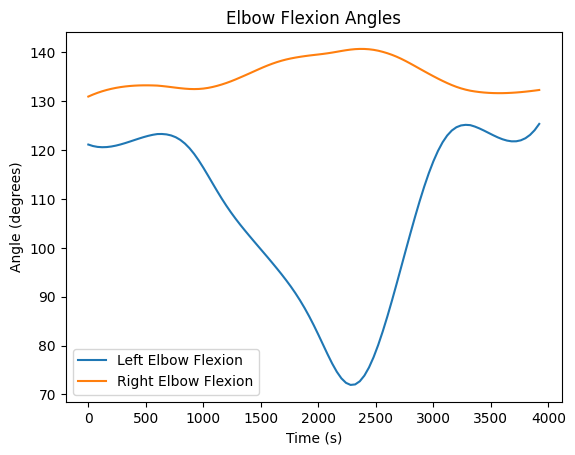

In [237]:
selected_jts = [
    "LEFT_SHOULDER",
    "RIGHT_SHOULDER",
    "LEFT_ELBOW",
    "RIGHT_ELBOW",
    "LEFT_WRIST",
    "RIGHT_WRIST",
    "LEFT_HIP",
    "RIGHT_HIP",
    "LEFT_INDEX",
    "RIGHT_INDEX",

]

def angle_2p_3d(a, b, c):
    v1 = np.array([a[0] - b[0], a[1] - b[1], a[2] - b[2]])
    v2 = np.array([c[0] - b[0], c[1] - b[1], c[2] - b[2]])

    v1mag = np.sqrt(v1[0]**2 + v1[1]**2 + v1[2]**2)
    v1norm = v1 / v1mag

    v2mag = np.sqrt(v2[0]**2 + v2[1]**2 + v2[2]**2)
    v2norm = v2 / v2mag

    res = np.dot(v1norm, v2norm)
    # Clip res to [-1, 1] to avoid numerical errors causing arccos domain error
    res = np.clip(res, -1.0, 1.0)
    angle_rad = np.arccos(res)

    return round(math.degrees(angle_rad), 2)

def get_mediapipe_joint_angles(kpts):
    left_shoulder_angle = angle_2p_3d(
        kpts[selected_jts.index("LEFT_ELBOW")],
        kpts[selected_jts.index("LEFT_SHOULDER")],
        kpts[selected_jts.index("LEFT_HIP")],
    )
    left_elbow_angle = angle_2p_3d(
        kpts[selected_jts.index("LEFT_WRIST")],
        kpts[selected_jts.index("LEFT_ELBOW")],
        kpts[selected_jts.index("LEFT_SHOULDER")],
    )
    left_wrist_angle = angle_2p_3d(
        kpts[selected_jts.index("LEFT_INDEX")],
        kpts[selected_jts.index("LEFT_WRIST")],
        kpts[selected_jts.index("LEFT_ELBOW")],
    )
    right_shoulder_angle = angle_2p_3d(
        kpts[selected_jts.index("RIGHT_ELBOW")],
        kpts[selected_jts.index("RIGHT_SHOULDER")],
        kpts[selected_jts.index("RIGHT_HIP")],
    )
    right_elbow_angle = angle_2p_3d(
        kpts[selected_jts.index("RIGHT_WRIST")],
        kpts[selected_jts.index("RIGHT_ELBOW")],
        kpts[selected_jts.index("RIGHT_SHOULDER")],
    )
    right_wrist_angle = angle_2p_3d(
        kpts[selected_jts.index("RIGHT_INDEX")],
        kpts[selected_jts.index("RIGHT_WRIST")],
        kpts[selected_jts.index("RIGHT_ELBOW")],
    )  

    return [
        left_shoulder_angle,
        left_elbow_angle,
        left_wrist_angle,
        right_shoulder_angle,
        right_elbow_angle,
        right_wrist_angle
    ]

def frame_to_kpts(frame_row):
    kpts = []
    for joint in selected_jts:
        x = frame_row[f"X_{joint}"]
        y = frame_row[f"Y_{joint}"]
        z = frame_row[f"Z_{joint}"]
        kpts.append([x, y, z])
    return kpts


all_angles = []
for index, row in sample.iterrows():
    kpts = frame_to_kpts(row)
    angles = get_mediapipe_joint_angles(kpts)
    all_angles.append(angles)

# Create a DataFrame from the angles
angles_df = pd.DataFrame(all_angles, columns=[
    "left_arm_flex",
    "left_elbow_flex",
    "left_wrist_flex",
    "right_arm_flex",
    "right_elbow_flex",
    "right_wrist_flex",
])

# Add time
angles_df['time'] = sample['time'].values
angles_df['fileID'] = sample['fileID'].values

# Smooth 
for col in angles_df.columns:
    if col != 'time' and col != 'fileID':
        angles_df[col] = scipy.signal.savgol_filter(angles_df[col], 31, 3)

# Plot the angles of right and left elbow
plt.plot(angles_df['time'], angles_df['left_elbow_flex'], label='Left Elbow Flexion')
plt.plot(angles_df['time'], angles_df['right_elbow_flex'], label='Right Elbow Flexion')
plt.xlabel('Time (s)')
plt.ylabel('Angle (degrees)')
plt.title('Elbow Flexion Angles')
plt.legend()
plt.show()




# Extra functions needed

In [ ]:
def compute_speed(df, keypoint):

    sr = df['time'].diff().mean()  # Sample rate in seconds
    x = df[f'X_{keypoint}']
    y = df[f'Y_{keypoint}']
    z = df[f'Z_{keypoint}']
    dist = np.sqrt((x.diff()**2 + y.diff()**2 + z.diff()**2))
    return dist * sr  # speed per second

# def detect_joint_glitches(df, joint='WRIST', speed_thresh=5.0, vis_thresh=0.3):
#     left_kp = f'LEFT_{joint}'
#     right_kp = f'RIGHT_{joint}'

#     sr = df['time'].diff().mean()

#     # Compute speed
#     speed_L = compute_speed(df, left_kp, sr)
#     speed_R = compute_speed(df, right_kp, sr)

#     # Crossover detection
#     crossover = (df[f'X_{left_kp}'] > df[f'X_{right_kp}']).astype(int)
#     crossover_event = crossover.diff().abs() > 0

#     # Visibility issues
#     low_vis = (
#         (df.get(f'{left_kp}_visibility', 1.0) < vis_thresh) |
#         (df.get(f'{right_kp}_visibility', 1.0) < vis_thresh)
#     )

#     # Flag glitches
#     glitch = (
#         crossover_event &
#         ((speed_L > speed_thresh) | (speed_R > speed_thresh)) &
#         low_vis
#     )

#     return pd.DataFrame({
#         f'{left_kp}_speed': speed_L,
#         f'{right_kp}_speed': speed_R,
#         f'{joint}_crossover': crossover_event,
#         f'{joint}_glitch': glitch
#     })

# def detect_all_joint_glitches(df):

#     sr = df['time'].diff().mean()
#     # Apply to both WRIST and ELBOW
#     glitch_data = []
#     for joint in ['WRIST', 'ELBOW']:
#         gd = detect_joint_glitches(df, joint=joint, fps=sr)
#         glitch_data.append(gd)

#     # Combine diagnostics
#     all_glitches = pd.concat(glitch_data, axis=1)
#     all_glitches['any_glitch'] = all_glitches.filter(like='_glitch').any(axis=1)

#     return all_glitches


def compute_angles(df):
    all_angles = []
    for index, row in df.iterrows():
        kpts = frame_to_kpts(row)
        angles = get_mediapipe_joint_angles(kpts)
        all_angles.append(angles)

    # Create a DataFrame from the angles
    angles_df = pd.DataFrame(all_angles, columns=[
        "left_arm_flex",
        "left_elbow_flex",
        "left_wrist_flex",
        "right_arm_flex",
        "right_elbow_flex",
        "right_wrist_flex"
    ])

    # Add time
    angles_df['time'] = df['time'].values
    angles_df['fileID'] = df['fileID'].values

    # Smooth the angles
    for col in angles_df.columns:
        if col != 'time' and col != 'fileID':
            angles_df[col] = scipy.signal.savgol_filter(angles_df[col], 31, 3)

    return angles_df

# Calculate speed of angles
def compute_angle_speed(angles_df):
    speed_cols = []

    # get the sr of the df
    sr = angles_df['time'].diff().mean()
    
    for col in angles_df.columns:
        if col not in ['time', 'fileID']:
            speed_col = f'{col}_speed'
            speed_cols.append(speed_col)
            # Differentiate
            angles_df[speed_col] = angles_df[col].diff() * sr
            # Smooth it
            angles_df[speed_col] = scipy.signal.savgol_filter(angles_df[speed_col], 21, 3)

    return angles_df, speed_cols


# Final code to process body files in Output_TimeSeries

In [247]:
error_list = []
#problems_glitches = []
problems_vis = []
missing_vis = []

os.makedirs(processedfolder, exist_ok=True)

# create txt file
f = open("error_log.txt", "w")

#for loop to go through every file in the timeseries folder
for file in bodyfiles:
    print("This is file" + str(file) + "// Count: " + str(bodyfiles.index(file)) + " of " + str(len(bodyfiles)) + " files in total")


    try:
        # Cleaning
        sample, problems_vis, missing_vis = clean_data(file, problems_vis, missing_vis)
        try:
            fileID = sample['fileID'][0]
        except:
            print('fileID not found')
            f.write(f'{fileID} fileID not found\n')
            continue

        sample = flip_data(sample)
        cols, sample = interpolate(sample)
        sample = smooth_data(sample)

        # Deriving
        sample = derive_speed_smooth(cols, sample)
        sample = derive_vertical_vel_smooth(sample)
        speedcols = [col for col in sample.columns if 'speed' in col]
        sample = derive_accel_smooth(speedcols, sample)
        sample = derive_jerk_smooth(sample)


        # Normalizing wrist by elbow and elbow by shoulder - speed
        if 'LEFT_WRIST_speed' in sample.columns and 'LEFT_ELBOW_speed' in sample.columns:
            sample['LEFT_WRIST_speed_norm'] = sample['LEFT_WRIST_speed'] / sample['LEFT_ELBOW_speed']
        if 'RIGHT_WRIST_speed' in sample.columns and 'RIGHT_ELBOW_speed' in sample.columns:
            sample['RIGHT_WRIST_speed_norm'] = sample['RIGHT_WRIST_speed'] / sample['RIGHT_ELBOW_speed']
        if 'LEFT_ELBOW_speed' in sample.columns and 'LEFT_SHOULDER_speed' in sample.columns:
            sample['LEFT_ELBOW_speed_norm'] = sample['LEFT_ELBOW_speed'] / sample['LEFT_SHOULDER_speed']
        if 'RIGHT_ELBOW_speed' in sample.columns and 'RIGHT_SHOULDER_speed' in sample.columns:
            sample['RIGHT_ELBOW_speed_norm'] = sample['RIGHT_ELBOW_speed'] / sample['RIGHT_SHOULDER_speed']

        # Normalizing wrist by elbow and elbow by shoulder - acceleration
        if 'LEFT_WRIST_acceleration' in sample.columns and 'LEFT_ELBOW_acceleration' in sample.columns:
            sample['LEFT_WRIST_acceleration_norm'] = sample['LEFT_WRIST_acceleration'] - sample['LEFT_ELBOW_acceleration']
        if 'RIGHT_WRIST_acceleration' in sample.columns and 'RIGHT_ELBOW_acceleration' in sample.columns:
            sample['RIGHT_WRIST_acceleration_norm'] = sample['RIGHT_WRIST_acceleration'] - sample['RIGHT_ELBOW_acceleration']
        if 'LEFT_ELBOW_acceleration' in sample.columns and 'LEFT_SHOULDER_acceleration' in sample.columns:
            sample['LEFT_ELBOW_acceleration_norm'] = sample['LEFT_ELBOW_acceleration'] - sample['LEFT_SHOULDER_acceleration']
        if 'RIGHT_ELBOW_acceleration' in sample.columns and 'RIGHT_SHOULDER_acceleration' in sample.columns:
            sample['RIGHT_ELBOW_acceleration_norm'] = sample['RIGHT_ELBOW_acceleration'] - sample['RIGHT_SHOULDER_acceleration']

        # Normalizing wrist by elbow and elbow by shoulder - jerk
        if 'LEFT_WRIST_jerk' in sample.columns and 'LEFT_ELBOW_jerk' in sample.columns:
            sample['LEFT_WRIST_jerk_norm'] = sample['LEFT_WRIST_jerk'] - sample['LEFT_ELBOW_jerk']
        if 'RIGHT_WRIST_jerk' in sample.columns and 'RIGHT_ELBOW_jerk' in sample.columns:
            sample['RIGHT_WRIST_jerk_norm'] = sample['RIGHT_WRIST_jerk'] - sample['RIGHT_ELBOW_jerk']
        if 'LEFT_ELBOW_jerk' in sample.columns and 'LEFT_SHOULDER_jerk' in sample.columns:
            sample['LEFT_ELBOW_jerk_norm'] = sample['LEFT_ELBOW_jerk'] - sample['LEFT_SHOULDER_jerk']
        if 'RIGHT_ELBOW_jerk' in sample.columns and 'RIGHT_SHOULDER_jerk' in sample.columns:
            sample['RIGHT_ELBOW_jerk_norm'] = sample['RIGHT_ELBOW_jerk'] - sample['RIGHT_SHOULDER_jerk']

        # # Add glitch detection
        # glitch_df = detect_all_joint_glitches(sample, fps=30)
        # if glitch_df['any_glitch'].sum() > 0:
        #     print(f'⚠️ Glitch detected in {fileID}')
        #     problems_glitches.append(fileID)

        # Calculating angles
        angles_df = compute_angles(sample)


        # Calculate speed of angles
        angles_df, speed_cols = compute_angle_speed(angles_df)

        # Concatenate on time
        sample = pd.merge(sample, angles_df, on='time', how='left')

        # Now get rid of all visibility columns
        sample = sample.drop([col for col in sample.columns if 'visibility' in col], axis=1)

        # Now I want to create some aggregated columns for arm speed (left+right shoulder, elbow, wrist) and arm angle speed (left+right shoulder, elbow, wrist flex speed) as euclidian distance
        sample['total_arm_speed'] = np.sqrt(
            sample['LEFT_SHOULDER_speed']**2 +
            sample['RIGHT_SHOULDER_speed']**2 +
            sample['LEFT_ELBOW_speed_norm']**2 +
            sample['RIGHT_ELBOW_speed_norm']**2 +
            sample['LEFT_WRIST_speed_norm']**2 +
            sample['RIGHT_WRIST_speed_norm']**2
        )

        # Total arm acceleration
        sample['total_arm_acceleration'] = np.sqrt(
            sample['LEFT_SHOULDER_acceleration']**2 +
            sample['RIGHT_SHOULDER_acceleration']**2 +
            sample['LEFT_ELBOW_acceleration_norm']**2 +
            sample['RIGHT_ELBOW_acceleration_norm']**2 +
            sample['LEFT_WRIST_acceleration_norm']**2 +
            sample['RIGHT_WRIST_acceleration_norm']**2
        )

        # Total arm jerk
        sample['total_arm_jerk'] = np.sqrt(
            sample['LEFT_SHOULDER_jerk']**2 +
            sample['RIGHT_SHOULDER_jerk']**2 +
            sample['LEFT_ELBOW_jerk_norm']**2 +
            sample['RIGHT_ELBOW_jerk_norm']**2 +
            sample['LEFT_WRIST_jerk_norm']**2 +
            sample['RIGHT_WRIST_jerk_norm']**2
        )

        # Total arm angle speed
        sample['total_arm_angle_speed'] = np.sqrt(
            sample['left_arm_flex_speed']**2 +
            sample['right_arm_flex_speed']**2 +
            sample['left_elbow_flex_speed']**2 +
            sample['right_elbow_flex_speed']**2 +
            sample['left_wrist_flex_speed']**2 +
            sample['right_wrist_flex_speed']**2
        )

        # Save
        globals()[fileID] = sample
        globals()[fileID].to_csv(os.path.join(processedfolder, f'{fileID}.csv'), index=False)

    except Exception as e:
        print(f"Error processing {file}: {e}")
        error_list.append(file)
        f.write(f'{file} {e}\n')
        continue
        #break
    
f.close()




This is filee:\VICOM_SignGes_Trajectory/Output_TimeSeries\flipped_IP06_02_ABHOLEN.mp4_body_world.csv// Count: 0 of 12869 files in total
This is filee:\VICOM_SignGes_Trajectory/Output_TimeSeries\GP02_AFFE.mp4_body_world.csv// Count: 1 of 12869 files in total
This is filee:\VICOM_SignGes_Trajectory/Output_TimeSeries\flipped_IP06_02_ABLEHNEN.mp4_body_world.csv// Count: 2 of 12869 files in total
This is filee:\VICOM_SignGes_Trajectory/Output_TimeSeries\GP02_ANFANG.mp4_body_world.csv// Count: 3 of 12869 files in total
This is filee:\VICOM_SignGes_Trajectory/Output_TimeSeries\GP02_ANGELN.mp4_body_world.csv// Count: 4 of 12869 files in total
This is filee:\VICOM_SignGes_Trajectory/Output_TimeSeries\GP02_ATEM.mp4_body_world.csv// Count: 5 of 12869 files in total
This is filee:\VICOM_SignGes_Trajectory/Output_TimeSeries\GP02_BART.mp4_body_world.csv// Count: 6 of 12869 files in total
This is filee:\VICOM_SignGes_Trajectory/Output_TimeSeries\flipped_IP06_02_AFFE.mp4_body_world.csv// Count: 7 of 1

This is how much files have problems with visibility

In [248]:
# Length of the unique instances
problems_vis = list(set(problems_vis))
len(problems_vis)

2082

In [ ]:
# Save it
with open('problems_visibility_all.txt', 'w') as f:
    for item in problems_vis:
        f.write("%s\n" % item)

# Checking of coordinate system

In [201]:
processedfiles = glob.glob(processedfolder + '*.csv')
print(processedfiles)

['e:\\VICOM_SignGes_Trajectory/TS_processed\\LP28_01_BASKETBALL_body_world.csv', 'e:\\VICOM_SignGes_Trajectory/TS_processed\\LP28_01_BEINE_body_world.csv', 'e:\\VICOM_SignGes_Trajectory/TS_processed\\LP28_01_BEOBACHTEN_body_world.csv', 'e:\\VICOM_SignGes_Trajectory/TS_processed\\LP28_01_BEZAHLEN_body_world.csv', 'e:\\VICOM_SignGes_Trajectory/TS_processed\\LP28_01_BIER_body_world.csv', 'e:\\VICOM_SignGes_Trajectory/TS_processed\\LP28_01_BILLIARD_body_world.csv', 'e:\\VICOM_SignGes_Trajectory/TS_processed\\LP28_01_BODEN_body_world.csv', 'e:\\VICOM_SignGes_Trajectory/TS_processed\\LP28_01_BRECHEN_body_world.csv', 'e:\\VICOM_SignGes_Trajectory/TS_processed\\LP28_01_BRIEF_body_world.csv', 'e:\\VICOM_SignGes_Trajectory/TS_processed\\LP28_01_BRILLE_body_world.csv', 'e:\\VICOM_SignGes_Trajectory/TS_processed\\LP28_01_BUCH_body_world.csv', 'e:\\VICOM_SignGes_Trajectory/TS_processed\\LP28_01_BUEGELN_body_world.csv', 'e:\\VICOM_SignGes_Trajectory/TS_processed\\LP28_01_DUSCHEN_body_world.csv', 'e:

In [ ]:
dgs = [x for x in processedfiles if 'DGS' in x]
dgs_concepts = [os.path.basename(x).split('_')[2] for x in dgs]

vicom = [x for x in processedfiles if 'ViCom' in os.path.basename(x)]
vicom_concepts = [os.path.basename(x).split('_')[3].split('.')[0] for x in vicom]

lp = [x for x in processedfiles if 'LP' in os.path.basename(x)]
lp_concepts = [os.path.basename(x).split('_')[2] for x in lp]

ip = [x for x in processedfiles if 'IP' in os.path.basename(x)]
ip_concepts = [os.path.basename(x).split('_')[2] for x in ip]

ges = [x for x in processedfiles if 'GP' in os.path.basename(x)]
ges_concepts = [os.path.basename(x).split('_')[1] for x in ges]


e:\VICOM_SignGes_Trajectory/TS_processed\GP10_SCHWEIN_body_world.csv


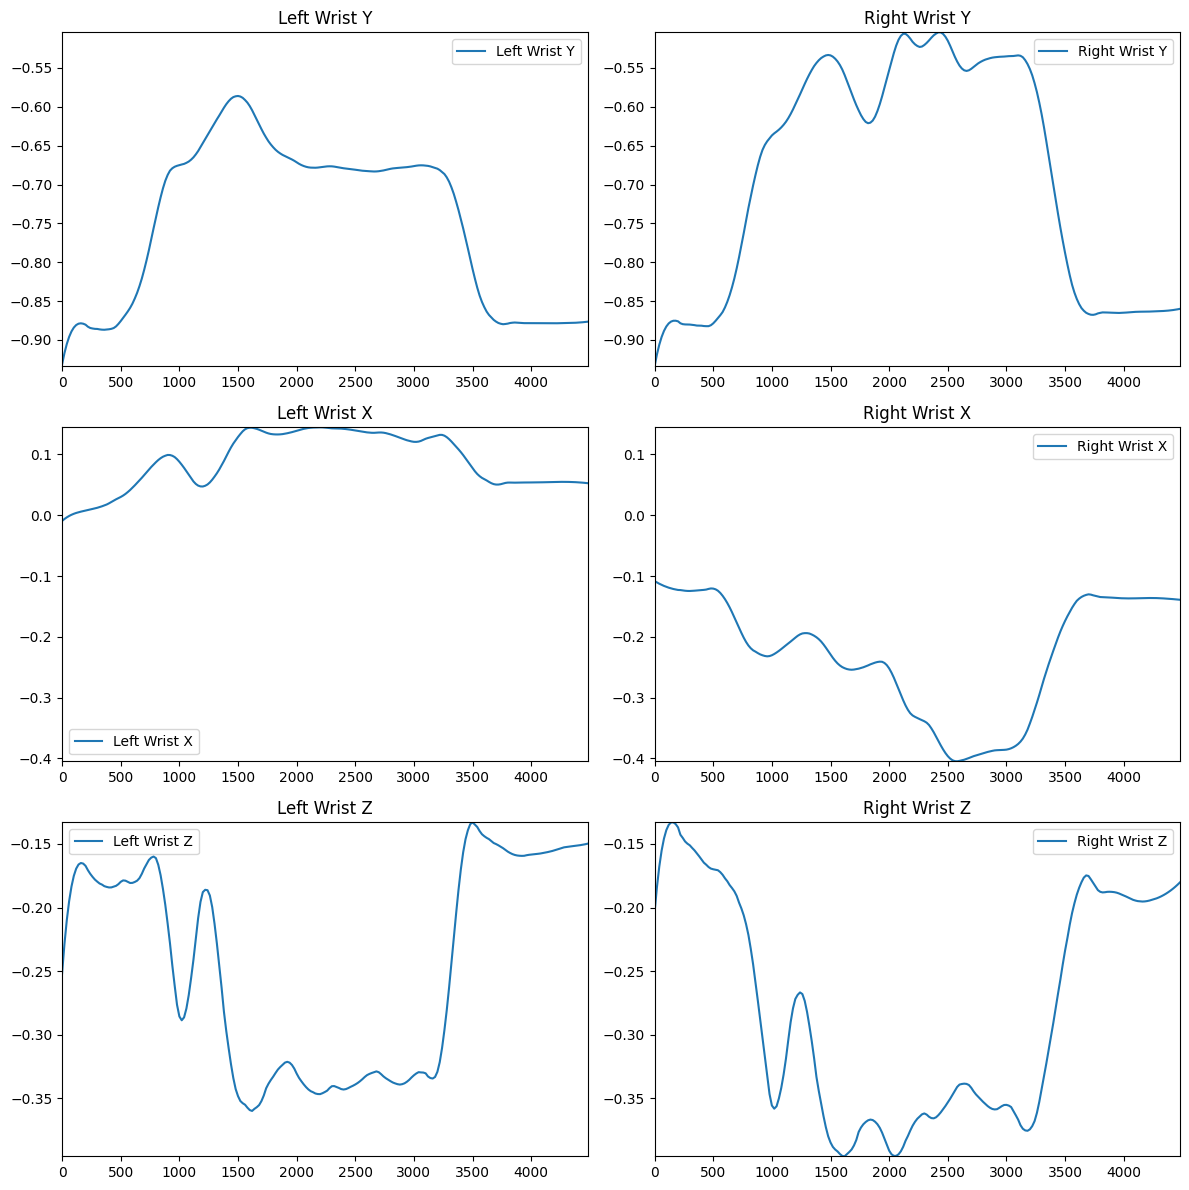

In [218]:
# pick a file
file = ges[7]
print(file)

# load the file
sample = pd.read_csv(file)

# let all axes have the same range (as max and min of the data)
max_y = max(sample['Y_LEFT_WRIST'].max(), sample['Y_RIGHT_WRIST'].max())
min_y = min(sample['Y_LEFT_WRIST'].min(), sample['Y_RIGHT_WRIST'].min())
max_x = max(sample['X_LEFT_WRIST'].max(), sample['X_RIGHT_WRIST'].max())
min_x = min(sample['X_LEFT_WRIST'].min(), sample['X_RIGHT_WRIST'].min())
max_z = max(sample['Z_LEFT_WRIST'].max(), sample['Z_RIGHT_WRIST'].max())
min_z = min(sample['Z_LEFT_WRIST'].min(), sample['Z_RIGHT_WRIST'].min())

# plot wrists, eahc dimension in separate grid
fig, axs = plt.subplots(3, 2, figsize=(12, 12))
axs[0, 0].plot(sample['time'], sample['Y_LEFT_WRIST'], label='Left Wrist Y')
axs[0, 0].set_title('Left Wrist Y')
axs[0, 1].plot(sample['time'], sample['Y_RIGHT_WRIST'], label='Right Wrist Y')
axs[0, 1].set_title('Right Wrist Y')
# set minmax
axs[0, 0].set_ylim(min_y, max_y)
axs[0, 1].set_ylim(min_y, max_y)

axs[1, 0].plot(sample['time'], sample['X_LEFT_WRIST'], label='Left Wrist X')
axs[1, 0].set_title('Left Wrist X')
axs[1, 1].plot(sample['time'], sample['X_RIGHT_WRIST'], label='Right Wrist X')
axs[1, 1].set_title('Right Wrist X')
axs[1, 0].set_ylim(min_x, max_x)
axs[1, 1].set_ylim(min_x, max_x)

axs[2, 0].plot(sample['time'], sample['Z_LEFT_WRIST'], label='Left Wrist Z')
axs[2, 0].set_title('Left Wrist Z')
axs[2, 1].plot(sample['time'], sample['Z_RIGHT_WRIST'], label='Right Wrist Z')
axs[2, 1].set_title('Right Wrist Z')
# set minmax
axs[2, 0].set_ylim(min_z, max_z)
axs[2, 1].set_ylim(min_z, max_z)

for ax in axs.flat:
    ax.set_xlim(sample['time'].min(), sample['time'].max())
    #ax.set_ylim(min_y, max_y)
    ax.legend()

plt.tight_layout()
plt.show()



In [219]:
# which overlap
overlap = set(dgs_concepts).intersection(set(vicom_concepts))
print("Overlapping concepts between DGS and ViCom:", overlap)

Overlapping concepts between DGS and ViCom: {'TABLE-TENNIS', 'TO-PUT-LIPSTICK-ON', 'SAW', 'COMMUNICATION', 'SPIDER', 'LETTER', 'TO-WASH-BODY', 'PIANO', 'PHONE-CALL', 'TO-IRON', 'PYRAMID', 'TO-EAT', 'MOTORBIKE', 'TO-PICK', 'PHOTOGRAPHY', 'SCREWDRIVER', 'LEGS', 'CLOTHES', 'TO-SMOKE', 'MASSAGE', 'PAST', 'TIME', 'EYE', 'WAR', 'TO-DRAW', 'SUITCASE', 'NOSE', 'GOAL', 'TO-KICK', 'TO-SHAVE', 'SANDWICH', 'CURTAIN', 'HOT', 'TO-COPY', 'TO-LIFT', 'FIRE', 'PILOT', 'TO-SEW', 'TO-INVITE', 'PLUG', 'TO-PICK-UP', 'TO-SLEEP', 'FLOOR', 'SPOON', 'HANDS', 'TO-PROPOSE', 'MONKEY', 'BOOK', 'GLASSES', 'TO-PUKE', 'MOSQUITO', 'WINE', 'PEPPER', 'TO-TURN-OFF', 'SCARF', 'TO-DIE', 'BEARD', 'HOCKEY', 'TO-PLAY-CARDS', 'COLD', 'TO-CLAP', 'LIGHTNING', 'TO-ERASE', 'CURIOUS', 'BIRTH', 'MILK', 'SURPRISED', 'A-LITTLE', 'LAPTOP', 'FENCE', 'TO-SCOLD', 'BABY', 'CALCULATOR', 'TO-BREAK', 'MIXER', 'ARM', 'TO-WAIT', 'DEVIL', 'TO-OBSERVE', 'BILLIARD', 'TO-DRINK', 'TEA', 'TENNIS', 'HAMMER', 'SUPERMARKET', 'SOCKS', 'A-LOT', 'PENGUIN', 

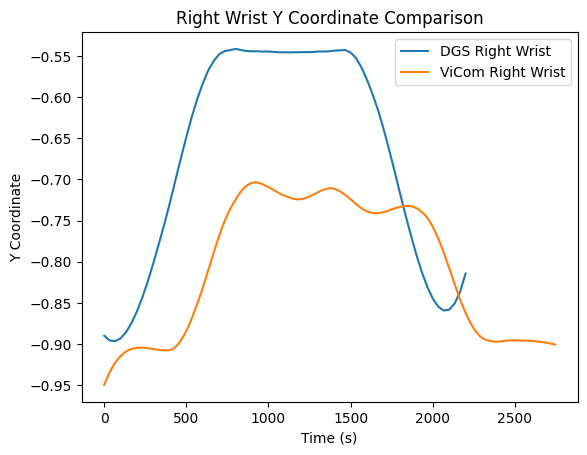

In [223]:
# get from both file with BUTTERFLY
dgs_s = [x for x in dgs if 'SNAKE' in os.path.basename(x)]
vicom_s = [x for x in vicom if 'SNAKE' in os.path.basename(x)]

df_dgs = pd.read_csv(dgs_s[0])
df_vicom = pd.read_csv(vicom_s[0])

# plot right wrist
plt.plot(df_dgs['time'], df_dgs['Y_RIGHT_WRIST'], label='DGS Right Wrist')
plt.plot(df_vicom['time'], df_vicom['Y_RIGHT_WRIST'], label='ViCom Right Wrist')
plt.xlabel('Time (s)')
plt.ylabel('Y Coordinate')
plt.title('Right Wrist Y Coordinate Comparison')
plt.legend()
plt.show()

Should we normalize by trunk height?

# Hand processing

# Final code to process hand files in Output_TimeSeries

In [149]:
outputcsv = glob.glob(mtfolder + '*.csv')  # Ensure outtputf_ts is defined
files = [x for x in outputcsv if 'hands_world' in x]
pxfiles = [x for x in outputcsv if 'hands' in x]
# but no world
pxfiles = [x for x in pxfiles if 'world' not in x]
pxsample = pd.read_csv(pxfiles[187])

In [168]:
# in pxfiles, find file with AKKORDEON and flipped
pxfiles = [x for x in pxfiles if 'AKKORDEON' in x and 'flipped' in x and 'IP06' in x]

In [169]:
pxfiles

['e:\\VICOM_SignGes_Trajectory/Output_TimeSeries\\flipped_IP06_02_AKKORDEON.mp4_hands.csv']

In [170]:
pxsample = pd.read_csv(pxfiles[0])

In [171]:
pxsample

,index,confidence,hand,time,X_WRIST,Y_WRIST,Z_WRIST,X_THUMB_CMC,Y_THUMB_CMC,Z_THUMB_CMC,...,Z_PINKY_MCP,X_PINKY_PIP,Y_PINKY_PIP,Z_PINKY_PIP,X_PINKY_DIP,Y_PINKY_DIP,Z_PINKY_DIP,X_PINKY_TIP,Y_PINKY_TIP,Z_PINKY_TIP
0,1,score: 0.998764336,"label: ""Right""",0,0.595193,0.812799,6.014593e-08,0.583596,0.791726,-0.002706,...,0.000684,0.550560,0.852976,-0.000288,0.545129,0.847592,0.000148,0.543396,0.841666,0.000801
1,2,score: 0.99918431,"label: ""Right""",40,0.596121,0.809095,7.200538e-08,0.583300,0.790659,-0.001631,...,0.001539,0.551173,0.848093,0.001391,0.545432,0.844037,0.002211,0.542486,0.840078,0.003003
2,3,score: 0.998618,"label: ""Right""",80,0.594960,0.808859,9.880554e-08,0.581952,0.789656,-0.001938,...,0.000805,0.552319,0.849800,0.000392,0.545771,0.846953,0.001190,0.541663,0.843374,0.001966
3,4,score: 0.998724401,"label: ""Right""",120,0.595034,0.809357,8.246430e-08,0.582178,0.790585,-0.001847,...,0.001278,0.551190,0.848578,0.000999,0.545385,0.844822,0.001935,0.542108,0.841002,0.002800
4,5,score: 0.998856485,"label: ""Right""",160,0.595098,0.810216,9.676359e-08,0.582495,0.790654,-0.002072,...,0.000950,0.552329,0.849679,0.000419,0.546060,0.846643,0.001147,0.542299,0.842982,0.001889
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
156,98,score: 0.908998,"label: ""Right""",3880,0.730069,0.521812,8.629168e-08,0.720798,0.496207,-0.000802,...,-0.017901,0.682430,0.547836,-0.022044,0.672995,0.553108,-0.024035,0.665218,0.557132,-0.025350
157,99,score: 0.994854331,"label: ""Left""",3920,0.420810,0.530206,-3.728453e-08,0.425483,0.510703,-0.001435,...,-0.016272,0.449916,0.524653,-0.017275,0.445257,0.528319,-0.014094,0.439018,0.529314,-0.012093
158,99,score: 0.893127322,"label: ""Right""",3920,0.738101,0.502909,1.021504e-07,0.728077,0.476681,-0.001092,...,-0.019741,0.693794,0.527187,-0.023872,0.684279,0.531902,-0.025649,0.676226,0.535378,-0.026819
159,100,score: 0.996051073,"label: ""Left""",3960,0.420813,0.524061,-4.129872e-08,0.424846,0.503590,-0.001063,...,-0.015935,0.450426,0.516540,-0.017035,0.446243,0.520059,-0.014166,0.439806,0.521231,-0.012288


First we need to redo the dataframe into timeseries form like we are used to

In [163]:
print('working on ', pxfiles[395])

working on  e:\VICOM_SignGes_Trajectory/Output_TimeSeries\IP06_02_GEFAENGNIS.mp4_hands.csv


In [130]:
print('working on ', files[187])

working on  e:\VICOM_SignGes_Trajectory/Output_TimeSeries\flipped_IP06_02_AKKORDEON.mp4_hands_world.csv


In [172]:
#sample = pd.read_csv(files[187])
sample = pxsample
# Get rid of all rows where is only NAN
sample = sample.dropna(how='all')
# Reset index
sample = sample.reset_index(drop=True)

# Make hand column simple left/right
sample['hand'] = sample['hand'].str.extract(r'label:\s*"([^"]+)"')[0]
# Get the name of the columns
hand_cols = sample.columns[4:]
hand_cols

# Make an empty df with column time + hand_cols that are combined with both _LEFT adnd _RIGHT

# to each hand_cols, add both _LEFT and _RIGHT
df = pd.DataFrame(columns=['time'])

for i in range(len(hand_cols)):
    newcolname_right = hand_cols[i] + '_RIGHT'
    newcolname_left = hand_cols[i] + '_LEFT'
    df[newcolname_right] = None
    df[newcolname_left] = None


C:\Users\kadava\AppData\Local\Temp\ipykernel_21104\2186801333.py:23: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[newcolname_left] = None
C:\Users\kadava\AppData\Local\Temp\ipykernel_21104\2186801333.py:22: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[newcolname_right] = None
C:\Users\kadava\AppData\Local\Temp\ipykernel_21104\2186801333.py:23: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at o

In [173]:
for i in range(len(sample)):
    df.loc[i, 'time'] = sample.loc[i, 'time']
    if sample.loc[i, 'hand'] == 'Right':
        for col in hand_cols:
            #print(sample.loc[i, col])
            df.loc[i, col + '_RIGHT'] = sample.loc[i, col]
            #df.loc[i, col + '_LEFT'] = None
    elif sample.loc[i, 'hand'] == 'Left':
        for col in hand_cols:
            df.loc[i, col + '_LEFT'] = sample.loc[i, col]
            #df.loc[i, col + '_RIGHT'] = None
    else:
        print(f"Unknown hand label at index {i}: {sample.loc[i, 'hand']}")

# Some rows are with repeating time, but have either only left or only right - merge those
df = df.groupby('time').first().reset_index()
    

In [141]:
df.head(   )

,time,X_WRIST_RIGHT,X_WRIST_LEFT,Y_WRIST_RIGHT,Y_WRIST_LEFT,Z_WRIST_RIGHT,Z_WRIST_LEFT,X_THUMB_CMC_RIGHT,X_THUMB_CMC_LEFT,Y_THUMB_CMC_RIGHT,...,Y_PINKY_DIP_RIGHT,Y_PINKY_DIP_LEFT,Z_PINKY_DIP_RIGHT,Z_PINKY_DIP_LEFT,X_PINKY_TIP_RIGHT,X_PINKY_TIP_LEFT,Y_PINKY_TIP_RIGHT,Y_PINKY_TIP_LEFT,Z_PINKY_TIP_RIGHT,Z_PINKY_TIP_LEFT
0,0,0.027075,None,-0.001105,None,0.05553,None,0.011575,None,-0.013631,...,0.010864,None,0.026248,None,-0.01862,None,0.00608,None,0.033839,None
1,40,0.034672,None,0.000295,None,0.056698,None,0.016022,None,-0.013147,...,0.013469,None,0.020936,None,-0.020465,None,0.010178,None,0.027591,None
2,80,0.033738,None,-0.002027,None,0.05266,None,0.01642,None,-0.014523,...,0.014443,None,0.012047,None,-0.01976,None,0.009727,None,0.017844,None
3,120,0.037802,None,-0.000879,None,0.054542,None,0.018066,None,-0.014789,...,0.014418,None,0.017259,None,-0.020594,None,0.01,None,0.022218,None
4,160,0.031975,None,0.00045,None,0.054353,None,0.014409,None,-0.012249,...,0.013455,None,0.013508,None,-0.01937,None,0.008945,None,0.018884,None


Check if we need to flip

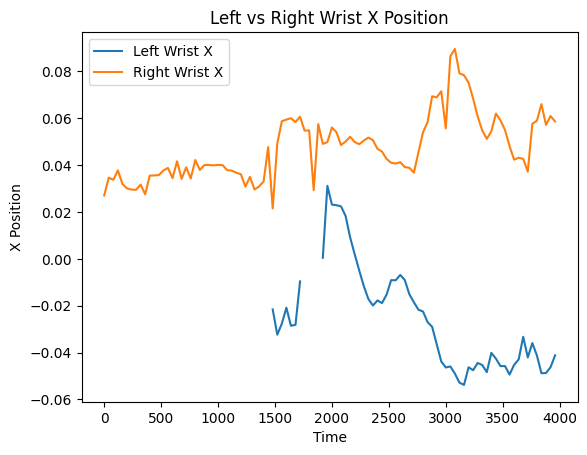

In [142]:
# plot right and left wrist
plt.plot(df['time'], df['X_WRIST_LEFT'], label='Left Wrist X')
plt.plot(df['time'], df['X_WRIST_RIGHT'], label='Right Wrist X')
plt.xlabel('Time')
plt.ylabel('X Position')
plt.title('Left vs Right Wrist X Position')
plt.legend()
plt.show()


non-world file

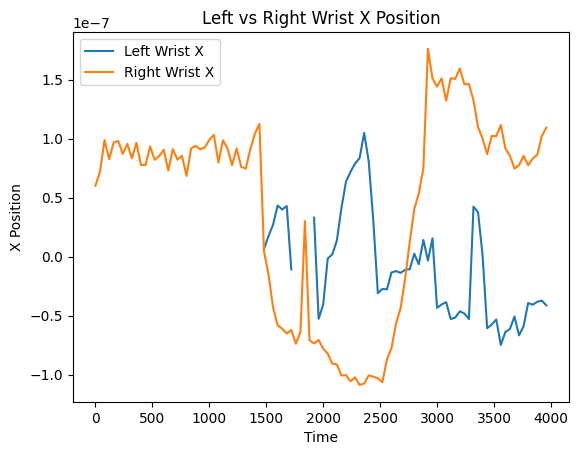

In [176]:
# plot right and left wrist
plt.plot(df['time'], df['Z_WRIST_LEFT'], label='Left Wrist X')
plt.plot(df['time'], df['Z_WRIST_RIGHT'], label='Right Wrist X')
plt.xlabel('Time')
plt.ylabel('X Position')
plt.title('Left vs Right Wrist X Position')
plt.legend()
plt.show()


In [54]:

# Load CSV file
outputcsv = glob.glob(mtfolder + '*.csv')  # Ensure outtputf_ts is defined
files = [x for x in outputcsv if 'hands_world' in x]
# find file with KITZELN in
files = [x for x in files if 'PUMPEN' in x and 'GP02' in x]
fileexample = files[0]
# load as df
MT_tracking = pd.read_csv(fileexample, index_col=False)

MT_tracking

,time,X_RIGHT_WRIST,Y_RIGHT_WRIST,Z_RIGHT_WRIST,X_RIGHT_THUMB_CMC,Y_RIGHT_THUMB_CMC,Z_RIGHT_THUMB_CMC,X_RIGHT_THUMB_MCP,Y_RIGHT_THUMB_MCP,Z_RIGHT_THUMB_MCP,...,Z_LEFT_PINKY_FINGER_MCP,X_LEFT_PINKY_FINGER_PIP,Y_LEFT_PINKY_FINGER_PIP,Z_LEFT_PINKY_FINGER_PIP,X_LEFT_PINKY_FINGER_DIP,Y_LEFT_PINKY_FINGER_DIP,Z_LEFT_PINKY_FINGER_DIP,X_LEFT_PINKY_FINGER_TIP,Y_LEFT_PINKY_FINGER_TIP,Z_LEFT_PINKY_FINGER_TIP
0,0.0,0.036182,-0.010912,0.066574,0.012435,-0.016804,0.051548,-0.005344,-0.009111,0.040595,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,20.0,0.041126,-0.016809,0.068040,0.018252,-0.024281,0.050088,-0.004199,-0.017167,0.038149,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,40.0,0.047914,-0.021070,0.069397,0.021544,-0.029333,0.050109,-0.004018,-0.024724,0.038257,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,60.0,0.047673,-0.021212,0.068413,0.020135,-0.027245,0.050558,-0.003718,-0.020995,0.039105,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,80.0,0.046542,-0.021143,0.069211,0.020524,-0.028367,0.049599,-0.003872,-0.022830,0.038045,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
220,4400.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
221,4420.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.008321,-0.014500,0.028646,-0.013729,-0.011416,0.032177,0.002650,-0.016667,0.026259,0.020559
222,4440.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.013680,-0.011688,0.032534,-0.017214,-0.008775,0.040605,0.001574,-0.019056,0.033881,0.013253
223,4460.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.014764,-0.012667,0.030346,-0.017472,-0.011807,0.039677,0.000005,-0.023041,0.033319,0.010259


In [55]:

# # Load CSV file
# outputcsv = glob.glob(mtfolder + '*.csv')  # Ensure outtputf_ts is defined
# files = [x for x in outputcsv if 'hands_world' in x]
# # find file with KITZELN in
# files = [x for x in files if 'KITZELN' in x and 'GP05' in x]
# fileexample = files[0]
# MT_tracking = pd.read_csv(fileexample, index_col=False)

# Create a figure and axis
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection='3d')

# Define the number of frames
num_frames = len(MT_tracking)

# Define the scatter plot
scatter = ax.scatter([], [], [], marker='o')

# Update function for animation
def update(frame):
    ax.clear()
    ax.set_xlabel('X Label')
    ax.set_ylabel('Z Label')
    ax.set_zlabel('Y Label')
    ax.set_title('3D Animation')
    
    # Set the limits of the axes based on the maximum values
    ax.set_xlim3d(0, 1)
    ax.set_ylim3d(20, 0)
    ax.set_zlim3d(0, 1) #we need to flip the vertical
    
    # Plot the data for the current frame
    frame_data = MT_tracking.iloc[frame]
    frame_data_body = MT_tracking.iloc[frame]
    x = frame_data.filter(like='X_')
    x_body = frame_data_body.filter(like='X_')
    y = frame_data.filter(like='Z_')
    y_body = frame_data_body.filter(like='Z_')
    z = frame_data.filter(like='Y_')
    z_body = frame_data_body.filter(like='Y_')
    # create scatter that has body in blue, and hands in red
    #scatter = ax.scatter(x, y, z, color='blue')
    scatter = ax.scatter(x_body, y_body, z_body*-1, color='red')

    return scatter

# Create the animation
ani = FuncAnimation(fig, update, frames=num_frames, interval=1000/30)

# Close the figure to prevent displaying the first frame
plt.close(fig)

# Save the animation as a video
ani.save('3D_animation_hands_check.mp4', writer='ffmpeg')

# Display the animation
video_path = '3D_animation_hands_check.mp4'
Video(video_path, embed=True, width=800)

ValueError: shape mismatch: objects cannot be broadcast to a single shape.  Mismatch is between arg 0 with shape (58,) and arg 1 with shape (42,).

In [ ]:
error_list = []
problems_glitches = []
problems_vis = []
missing_vis = []

os.makedirs(processedfolder, exist_ok=True)

# create txt file
f = open("error_log_hands.txt", "w")

#for loop to go through every file in the timeseries folder
for file in tqdm (bodyfiles, desc='Processing body files'):
    print('working on', file)


    try:
        # Cleaning
        sample, problems_vis, missing_vis = clean_data(file, problems_vis, missing_vis)
        try:
            fileID = sample['fileID'][0]
        except:
            print('fileID not found')
            f.write(f'{fileID} fileID not found\n')
            continue

        sample = flip_data(sample)
        cols, sample = interpolate(sample)
        sample = smooth_data(sample)

        # Deriving
        sample = derive_speed_smooth(cols, sample)
        sample = derive_vertical_vel_smooth(sample)
        speedcols = [col for col in sample.columns if 'speed' in col]
        sample = derive_accel_smooth(speedcols, sample)
        sample = derive_jerk_smooth(sample)

        # Add glitch detection
        glitch_df = detect_all_joint_glitches(sample, fps=30)
        if glitch_df['any_glitch'].sum() > 0:
            print(f'⚠️ Glitch detected in {fileID}')
            problems_glitches.append(fileID)

        # Calculating angles
        angles_df = compute_angles(sample)
        # Calculate speed of angles
        angles_df, speed_cols = compute_angle_speed(angles_df, fps=30)
        # Concatenate on time
        sample = pd.merge(sample, angles_df, on='time', how='left')

        # Now get rid of all visibility columns
        sample = sample.drop([col for col in sample.columns if 'visibility' in col], axis=1)

        # Now I want to create some aggregated columns for arm speed (left+right shoulder, elbow, wrist) and arm angle speed (left+right shoulder, elbow, wrist flex speed) as euclidian distance
        sample['total_arm_speed'] = np.sqrt(
            sample['LEFT_SHOULDER_speed']**2 +
            sample['RIGHT_SHOULDER_speed']**2 +
            sample['LEFT_ELBOW_speed']**2 +
            sample['RIGHT_ELBOW_speed']**2 +
            sample['LEFT_WRIST_speed']**2 +
            sample['RIGHT_WRIST_speed']**2
        )

        # Total arm acceleration
        sample['total_arm_acceleration'] = np.sqrt(
            sample['LEFT_SHOULDER_acceleration']**2 +
            sample['RIGHT_SHOULDER_acceleration']**2 +
            sample['LEFT_ELBOW_acceleration']**2 +
            sample['RIGHT_ELBOW_acceleration']**2 +
            sample['LEFT_WRIST_acceleration']**2 +
            sample['RIGHT_WRIST_acceleration']**2
        )

        # Total arm jerk
        sample['total_arm_jerk'] = np.sqrt(
            sample['LEFT_SHOULDER_jerk']**2 +
            sample['RIGHT_SHOULDER_jerk']**2 +
            sample['LEFT_ELBOW_jerk']**2 +
            sample['RIGHT_ELBOW_jerk']**2 +
            sample['LEFT_WRIST_jerk']**2 +
            sample['RIGHT_WRIST_jerk']**2
        )

        # Total arm angle speed
        sample['total_arm_angle_speed'] = np.sqrt(
            sample['left_arm_flex_speed']**2 +
            sample['right_arm_flex_speed']**2 +
            sample['left_elbow_flex_speed']**2 +
            sample['right_elbow_flex_speed']**2 +
            sample['left_wrist_flex_speed']**2 +
            sample['right_wrist_flex_speed']**2
        )

        # Save
        globals()[fileID] = sample
        globals()[fileID].to_csv(os.path.join(processedfolder, f'{fileID}.csv'), index=False)

    except Exception as e:
        print(f"Error processing {file}: {e}")
        error_list.append(file)
        f.write(f'{file} {e}\n')
        continue
    
f.close()




## Joint distances for hand

We will now compute the joint angles, operationalized simply as a distance of the neighboring joints. 

In [25]:
def gethandjointdistance(sample, dictionary, joint1number, joint2number):

    # map the joint number to the joint name, based on the dictionary
    joint1 = dictionary[joint1number]
    joint2 = dictionary[joint2number]

    # left hand
    joint1x_l = sample['X_LEFT_' + joint1]
    joint1y_l = sample['Y_LEFT_' + joint1]
    joint1z_l = sample['Z_LEFT_' + joint1]

    joint2x_l = sample['X_LEFT_' + joint2]
    joint2y_l = sample['Y_LEFT_' + joint2]
    joint2z_l = sample['Z_LEFT_' + joint2]

    # right hand
    joint1x_r = sample['X_RIGHT_' + joint1]
    joint1y_r = sample['Y_RIGHT_' + joint1]
    joint1z_r = sample['Z_RIGHT_' + joint1]

    joint2x_r = sample['X_RIGHT_' + joint2]
    joint2y_r = sample['Y_RIGHT_' + joint2]
    joint2z_r = sample['Z_RIGHT_' + joint2]

    # get the x, y, z columns for both hands
    x1_l = joint1x_l
    y1_l = joint1y_l
    z1_l = joint1z_l
    x2_l = joint2x_l
    y2_l = joint2y_l
    z2_l = joint2z_l   

    x1_r = joint1x_r
    y1_r = joint1y_r
    z1_r = joint1z_r
    x2_r = joint2x_r
    y2_r = joint2y_r
    z2_r = joint2z_r 


    # calculate the distance for each dimension separately
    dist_x_l = x1_l - x2_l
    dist_y_l = y1_l - y2_l
    dist_z_l = z1_l - z2_l

    dist_x_r = x1_r - x2_r
    dist_y_r = y1_r - y2_r
    dist_z_r = z1_r - z2_r

    # calculate the total distance
    dist_l = np.sqrt(dist_x_l ** 2 + dist_y_l ** 2 + dist_z_l ** 2)
    dist_r = np.sqrt(dist_x_r ** 2 + dist_y_r ** 2 + dist_z_r ** 2)

    return dist_x_l, dist_y_l, dist_z_l, dist_l, dist_x_r, dist_y_r, dist_z_r, dist_r

### Derive speed, etc.

In [26]:
# for each column that doesn't have _x, _y, _z, calculate speed, acceleration, and jerk

def derive_speed_accel_jerk(df):
    cols = df.columns
    cols = cols.drop(['time', 'fileID'])
    for col in cols:
        if '_x' not in col and '_y' not in col and '_z' not in col:
            # calculate speed
            df[col + '_speed'] = np.insert(np.diff(df[col]), 0, 0)
            # absolutize
            df[col + '_speed'] = np.abs(df[col + '_speed'])
            # smooth it
            df[col + '_speed'] = scipy.signal.savgol_filter(df[col + '_speed'], 15, 3)
            # calculate acceleration
            df[col + '_acceleration'] = np.insert(np.diff(df[col + '_speed']), 0, 0)
            # smooth it
            df[col + '_acceleration'] = scipy.signal.savgol_filter(df[col + '_acceleration'], 15, 3)
            # calculate jerk
            df[col + '_jerk'] = np.insert(np.diff(df[col + '_acceleration']), 0, 0)
            # smooth it
            df[col + '_jerk'] = scipy.signal.savgol_filter(df[col + '_jerk'], 15, 3)
    return df

### Loop and get distances - hand


We will follow mediapipe annotation of hand and used the numbers

**here is the picture**


![Hand keypoints](hand_landmarks_mediapipe.png)

In [17]:
import warnings
warnings.filterwarnings('ignore')

hand_distances = {}
df_all = pd.DataFrame()
handfiles = glob.glob(processedfolder + '*hands_world*.csv')
# keep only those tha have GP in the name
handfiles = [x for x in handfiles if 'GP' in x]

print(handfiles)

# create dictionary to map hand keypoint to a number
handkeypoints_mp = {'WRIST': 0, 'THUMB_CMC': 1, 'THUMB_MCP': 2, 'THUMB_IP': 3, 'THUMB_TIP': 4,
                 'INDEX_FINGER_MCP': 5, 'INDEX_FINGER_PIP': 6, 'INDEX_FINGER_DIP': 7, 'INDEX_FINGER_TIP': 8,
                 'MIDDLE_FINGER_MCP': 9, 'MIDDLE_FINGER_PIP': 10, 'MIDDLE_FINGER_DIP': 11, 'MIDDLE_FINGER_TIP': 12,
                 'RING_FINGER_MCP': 13, 'RING_FINGER_PIP': 14, 'RING_FINGER_DIP': 15, 'RING_FINGER_TIP': 16,
                 'PINKY_FINGER_MCP': 17, 'PINKY_FINGER_PIP': 18, 'PINKY_FINGER_DIP': 19, 'PINKY_FINGER_TIP': 20}

#make a dictionary that is flipped version of the handkeypoints
handkeypoints = {v: k for k, v in handkeypoints_mp.items()}

for file in handfiles:
    print(file)
    df = pd.read_csv(file)
    try:
        fileID = df['fileID'][0]
    except KeyError:
        continue

    # get rid of all speed, velocity, acceleration, and jerk columns
    df = df.drop([col for col in df.columns if 'speed' in col], axis=1)
    df = df.drop([col for col in df.columns if 'velocity' in col], axis=1)
    df = df.drop([col for col in df.columns if 'acceleration' in col], axis=1)
    df = df.drop([col for col in df.columns if 'jerk' in col], axis=1)

    # get distance between 4-2, 4-1, 3-1, 4-17, 2-0, 3-0, 4-0 by finding the mapping of the keypoint to the number (for each hand)
    l4_2_x, l4_2_y, l4_2_z, l4_2, r4_2_x, r4_2_y, r4_2_z, r4_2 = gethandjointdistance(df, handkeypoints, 4, 2)
    l4_1_x, l4_1_y, l4_1_z, l4_1, r4_1_x, r4_1_y, r4_1_z, r4_1 = gethandjointdistance(df, handkeypoints, 4, 1)
    l3_1_x, l3_1_y, l3_1_z, l3_1, r3_1_x, r3_1_y, r3_1_z, r3_1 = gethandjointdistance(df, handkeypoints, 3, 1)
    l4_17_x, l4_17_y, l4_17_z, l4_17, r4_17_x, r4_17_y, r4_17_z, r4_17 = gethandjointdistance(df, handkeypoints, 4, 17)
    l2_0_x, l2_0_y, l2_0_z, l2_0, r2_0_x, r2_0_y, r2_0_z, r2_0 = gethandjointdistance(df, handkeypoints, 2, 0)
    l3_0_x, l3_0_y, l3_0_z, l3_0, r3_0_x, r3_0_y, r3_0_z, r3_0 = gethandjointdistance(df, handkeypoints, 3, 0)
    l4_0_x, l4_0_y, l4_0_z, l4_0, r4_0_x, r4_0_y, r4_0_z, r4_0 = gethandjointdistance(df, handkeypoints, 4, 0)

    # get distance between 8-6, 7-5, 8-5, 6-0, 7-0, 8-0
    l8_6_x, l8_6_y, l8_6_z, l8_6, r8_6_x, r8_6_y, r8_6_z, r8_6 = gethandjointdistance(df, handkeypoints, 8, 6)
    l7_5_x, l7_5_y, l7_5_z, l7_5, r7_5_x, r7_5_y, r7_5_z, r7_5 = gethandjointdistance(df, handkeypoints, 7, 5)
    l8_5_x, l8_5_y, l8_5_z, l8_5, r8_5_x, r8_5_y, r8_5_z, r8_5 = gethandjointdistance(df, handkeypoints, 8, 5)
    l6_0_x, l6_0_y, l6_0_z, l6_0, r6_0_x, r6_0_y, r6_0_z, r6_0 = gethandjointdistance(df, handkeypoints, 6, 0)
    l7_0_x, l7_0_y, l7_0_z, l7_0, r7_0_x, r7_0_y, r7_0_z, r7_0 = gethandjointdistance(df, handkeypoints, 7, 0)
    l8_0_x, l8_0_y, l8_0_z, l8_0, r8_0_x, r8_0_y, r8_0_z, r8_0 = gethandjointdistance(df, handkeypoints, 8, 0)

    # get distances between 12-10, 11-9, 12-9, 10-0, 11-0, 12-0
    l12_10_x, l12_10_y, l12_10_z, l12_10, r12_10_x, r12_10_y, r12_10_z, r12_10 = gethandjointdistance(df, handkeypoints, 12, 10)
    l11_9_x, l11_9_y, l11_9_z, l11_9, r11_9_x, r11_9_y, r11_9_z, r11_9 = gethandjointdistance(df, handkeypoints, 11, 9)
    l12_9_x, l12_9_y, l12_9_z, l12_9, r12_9_x, r12_9_y, r12_9_z, r12_9 = gethandjointdistance(df, handkeypoints, 12, 9)
    l10_0_x, l10_0_y, l10_0_z, l10_0, r10_0_x, r10_0_y, r10_0_z, r10_0 = gethandjointdistance(df, handkeypoints, 10, 0)
    l11_0_x, l11_0_y, l11_0_z, l11_0, r11_0_x, r11_0_y, r11_0_z, r11_0 = gethandjointdistance(df, handkeypoints, 11, 0)
    l12_0_x, l12_0_y, l12_0_z, l12_0, r12_0_x, r12_0_y, r12_0_z, r12_0 = gethandjointdistance(df, handkeypoints, 12, 0)

    # get distances between 16-14, 15-13, 16-13, 14-0, 15-0, 16-0
    l16_14_x, l16_14_y, l16_14_z, l16_14, r16_14_x, r16_14_y, r16_14_z, r16_14 = gethandjointdistance(df, handkeypoints, 16, 14)
    l15_13_x, l15_13_y, l15_13_z, l15_13, r15_13_x, r15_13_y, r15_13_z, r15_13 = gethandjointdistance(df, handkeypoints, 15, 13)
    l16_13_x, l16_13_y, l16_13_z, l16_13, r16_13_x, r16_13_y, r16_13_z, r16_13 = gethandjointdistance(df, handkeypoints, 16, 13)
    l14_0_x, l14_0_y, l14_0_z, l14_0, r14_0_x, r14_0_y, r14_0_z, r14_0 = gethandjointdistance(df, handkeypoints, 14, 0)
    l15_0_x, l15_0_y, l15_0_z, l15_0, r15_0_x, r15_0_y, r15_0_z, r15_0 = gethandjointdistance(df, handkeypoints, 15, 0)
    l16_0_x, l16_0_y, l16_0_z, l16_0, r16_0_x, r16_0_y, r16_0_z, r16_0 = gethandjointdistance(df, handkeypoints, 16, 0)

    # get distances between 20-18, 19-17, 20-17, 18-0, 19-0, 20-0
    l20_18_x, l20_18_y, l20_18_z, l20_18, r20_18_x, r20_18_y, r20_18_z, r20_18 = gethandjointdistance(df, handkeypoints, 20, 18)
    l19_17_x, l19_17_y, l19_17_z, l19_17, r19_17_x, r19_17_y, r19_17_z, r19_17 = gethandjointdistance(df, handkeypoints, 19, 17)
    l20_17_x, l20_17_y, l20_17_z, l20_17, r20_17_x, r20_17_y, r20_17_z, r20_17 = gethandjointdistance(df, handkeypoints, 20, 17)
    l18_0_x, l18_0_y, l18_0_z, l18_0, r18_0_x, r18_0_y, r18_0_z, r18_0 = gethandjointdistance(df, handkeypoints, 18, 0)
    l19_0_x, l19_0_y, l19_0_z, l19_0, r19_0_x, r19_0_y, r19_0_z, r19_0 = gethandjointdistance(df, handkeypoints, 19, 0)
    l20_0_x, l20_0_y, l20_0_z, l20_0, r20_0_x, r20_0_y, r20_0_z, r20_0 = gethandjointdistance(df, handkeypoints, 20, 0)

    # get distances between fingers - 4-8, 8-12, 12-16, 16-20
    l4_8_x, l4_8_y, l4_8_z, l4_8, r4_8_x, r4_8_y, r4_8_z, r4_8 = gethandjointdistance(df, handkeypoints, 4, 8)
    l8_12_x, l8_12_y, l8_12_z, l8_12, r8_12_x, r8_12_y, r8_12_z, r8_12 = gethandjointdistance(df, handkeypoints, 8, 12)
    l12_16_x, l12_16_y, l12_16_z, l12_16, r12_16_x, r12_16_y, r12_16_z, r12_16 = gethandjointdistance(df, handkeypoints, 12, 16)
    l16_20_x, l16_20_y, l16_20_z, l16_20, r16_20_x, r16_20_y, r16_20_z, r16_20 = gethandjointdistance(df, handkeypoints, 16, 20)

    # save all variables into a dictionary
    hand_distances[fileID] = {'l4_2_x': l4_2_x, 'l4_2_y': l4_2_y, 'l4_2_z': l4_2_z, 'l4_2': l4_2, 'r4_2_x': r4_2_x, 'r4_2_y': r4_2_y, 'r4_2_z': r4_2_z, 'r4_2': r4_2,
                                'l4_1_x': l4_1_x, 'l4_1_y': l4_1_y, 'l4_1_z': l4_1_z, 'l4_1': l4_1, 'r4_1_x': r4_1_x, 'r4_1_y': r4_1_y, 'r4_1_z': r4_1_z, 'r4_1': r4_1,
                                'l3_1_x': l3_1_x, 'l3_1_y': l3_1_y, 'l3_1_z': l3_1_z, 'l3_1': l3_1, 'r3_1_x': r3_1_x, 'r3_1_y': r3_1_y, 'r3_1_z': r3_1_z, 'r3_1': r3_1,
                                'l4_17_x': l4_17_x, 'l4_17_y': l4_17_y, 'l4_17_z': l4_17_z, 'l4_17': l4_17, 'r4_17_x': r4_17_x, 'r4_17_y': r4_17_y, 'r4_17_z': r4_17_z, 'r4_17': r4_17,
                                'l2_0_x': l2_0_x, 'l2_0_y': l2_0_y, 'l2_0_z': l2_0_z, 'l2_0': l2_0, 'r2_0_x': r2_0_x, 'r2_0_y': r2_0_y, 'r2_0_z': r2_0_z, 'r2_0': r2_0,
                                'l3_0_x': l3_0_x, 'l3_0_y': l3_0_y, 'l3_0_z': l3_0_z, 'l3_0': l3_0, 'r3_0_x': r3_0_x, 'r3_0_y': r3_0_y, 'r3_0_z': r3_0_z, 'r3_0': r3_0,
                                'l4_0_x': l4_0_x, 'l4_0_y': l4_0_y, 'l4_0_z': l4_0_z, 'l4_0': l4_0, 'r4_0_x': r4_0_x, 'r4_0_y': r4_0_y, 'r4_0_z': r4_0_z, 'r4_0': r4_0,
                                'l8_6_x': l8_6_x, 'l8_6_y': l8_6_y, 'l8_6_z': l8_6_z, 'l8_6': l8_6, 'r8_6_x': r8_6_x, 'r8_6_y': r8_6_y, 'r8_6_z': r8_6_z, 'r8_6': r8_6,
                                'l7_5_x': l7_5_x, 'l7_5_y': l7_5_y, 'l7_5_z': l7_5_z, 'l7_5': l7_5, 'r7_5_x': r7_5_x, 'r7_5_y': r7_5_y, 'r7_5_z': r7_5_z, 'r7_5': r7_5,
                                'l8_5_x': l8_5_x, 'l8_5_y': l8_5_y, 'l8_5_z': l8_5_z, 'l8_5': l8_5, 'r8_5_x': r8_5_x, 'r8_5_y': r8_5_y, 'r8_5_z': r8_5_z, 'r8_5': r8_5,
                                'l6_0_x': l6_0_x, 'l6_0_y': l6_0_y, 'l6_0_z': l6_0_z, 'l6_0': l6_0, 'r6_0_x': r6_0_x, 'r6_0_y': r6_0_y, 'r6_0_z': r6_0_z, 'r6_0': r6_0,
                                'l7_0_x': l7_0_x, 'l7_0_y': l7_0_y, 'l7_0_z': l7_0_z, 'l7_0': l7_0, 'r7_0_x': r7_0_x, 'r7_0_y': r7_0_y, 'r7_0_z': r7_0_z, 'r7_0': r7_0,
                                'l8_0_x': l8_0_x, 'l8_0_y': l8_0_y, 'l8_0_z': l8_0_z, 'l8_0': l8_0, 'r8_0_x': r8_0_x, 'r8_0_y': r8_0_y, 'r8_0_z': r8_0_z, 'r8_0': r8_0,
                                'l12_10_x': l12_10_x, 'l12_10_y': l12_10_y, 'l12_10_z': l12_10_z, 'l12_10': l12_10, 'r12_10_x': r12_10_x, 'r12_10_y': r12_10_y, 'r12_10_z': r12_10_z, 'r12_10': r12_10,
                                'l11_9_x': l11_9_x, 'l11_9_y': l11_9_y, 'l11_9_z': l11_9_z, 'l11_9': l11_9, 'r11_9_x': r11_9_x, 'r11_9_y': r11_9_y, 'r11_9_z': r11_9_z, 'r11_9': r11_9,
                                'l12_9_x': l12_9_x, 'l12_9_y': l12_9_y, 'l12_9_z': l12_9_z, 'l12_9': l12_9, 'r12_9_x': r12_9_x, 'r12_9_y': r12_9_y, 'r12_9_z': r12_9_z, 'r12_9': r12_9,
                                'l10_0_x': l10_0_x, 'l10_0_y': l10_0_y, 'l10_0_z': l10_0_z, 'l10_0': l10_0, 'r10_0_x': r10_0_x, 'r10_0_y': r10_0_y, 'r10_0_z': r10_0_z, 'r10_0': r10_0,
                                'l11_0_x': l11_0_x, 'l11_0_y': l11_0_y, 'l11_0_z': l11_0_z, 'l11_0': l11_0, 'r11_0_x': r11_0_x, 'r11_0_y': r11_0_y, 'r11_0_z': r11_0_z, 'r11_0': r11_0,
                                'l12_0_x': l12_0_x, 'l12_0_y': l12_0_y, 'l12_0_z': l12_0_z, 'l12_0': l12_0, 'r12_0_x': r12_0_x, 'r12_0_y': r12_0_y, 'r12_0_z': r12_0_z, 'r12_0': r12_0,
                                'l16_14_x': l16_14_x, 'l16_14_y': l16_14_y, 'l16_14_z': l16_14_z, 'l16_14': l16_14, 'r16_14_x': r16_14_x, 'r16_14_y': r16_14_y, 'r16_14_z': r16_14_z, 'r16_14': r16_14,
                                'l15_13_x': l15_13_x, 'l15_13_y': l15_13_y, 'l15_13_z': l15_13_z, 'l15_13': l15_13, 'r15_13_x': r15_13_x, 'r15_13_y': r15_13_y, 'r15_13_z': r15_13_z, 'r15_13': r15_13,
                                'l16_13_x': l16_13_x, 'l16_13_y': l16_13_y, 'l16_13_z': l16_13_z, 'l16_13': l16_13, 'r16_13_x': r16_13_x, 'r16_13_y': r16_13_y, 'r16_13_z': r16_13_z, 'r16_13': r16_13,
                                'l14_0_x': l14_0_x, 'l14_0_y': l14_0_y, 'l14_0_z': l14_0_z, 'l14_0': l14_0, 'r14_0_x': r14_0_x, 'r14_0_y': r14_0_y, 'r14_0_z': r14_0_z, 'r14_0': r14_0,
                                'l15_0_x': l15_0_x, 'l15_0_y': l15_0_y, 'l15_0_z': l15_0_z, 'l15_0': l15_0, 'r15_0_x': r15_0_x, 'r15_0_y': r15_0_y, 'r15_0_z': r15_0_z, 'r15_0': r15_0,
                                'l16_0_x': l16_0_x, 'l16_0_y': l16_0_y, 'l16_0_z': l16_0_z, 'l16_0': l16_0, 'r16_0_x': r16_0_x, 'r16_0_y': r16_0_y, 'r16_0_z': r16_0_z, 'r16_0': r16_0,
                                'l20_18_x': l20_18_x, 'l20_18_y': l20_18_y, 'l20_18_z': l20_18_z, 'l20_18': l20_18, 'r20_18_x': r20_18_x, 'r20_18_y': r20_18_y, 'r20_18_z': r20_18_z, 'r20_18': r20_18,
                                'l19_17_x': l19_17_x, 'l19_17_y': l19_17_y, 'l19_17_z': l19_17_z, 'l19_17': l19_17, 'r19_17_x': r19_17_x, 'r19_17_y': r19_17_y, 'r19_17_z': r19_17_z, 'r19_17': r19_17,
                                'l20_17_x': l20_17_x, 'l20_17_y': l20_17_y, 'l20_17_z': l20_17_z, 'l20_17': l20_17, 'r20_17_x': r20_17_x, 'r20_17_y': r20_17_y, 'r20_17_z': r20_17_z, 'r20_17': r20_17,
                                'l18_0_x': l18_0_x, 'l18_0_y': l18_0_y, 'l18_0_z': l18_0_z, 'l18_0': l18_0, 'r18_0_x': r18_0_x, 'r18_0_y': r18_0_y, 'r18_0_z': r18_0_z, 'r18_0': r18_0,
                                'l19_0_x': l19_0_x, 'l19_0_y': l19_0_y, 'l19_0_z': l19_0_z, 'l19_0': l19_0, 'r19_0_x': r19_0_x, 'r19_0_y': r19_0_y, 'r19_0_z': r19_0_z, 'r19_0': r19_0,
                                'l20_0_x': l20_0_x, 'l20_0_y': l20_0_y, 'l20_0_z': l20_0_z, 'l20_0': l20_0, 'r20_0_x': r20_0_x, 'r20_0_y': r20_0_y, 'r20_0_z': r20_0_z, 'r20_0': r20_0,
                                'l4_8_x': l4_8_x, 'l4_8_y': l4_8_y, 'l4_8_z': l4_8_z, 'l4_8': l4_8, 'r4_8_x': r4_8_x, 'r4_8_y': r4_8_y, 'r4_8_z': r4_8_z, 'r4_8': r4_8,
                                'l8_12_x': l8_12_x, 'l8_12_y': l8_12_y, 'l8_12_z': l8_12_z, 'l8_12': l8_12, 'r8_12_x': r8_12_x, 'r8_12_y': r8_12_y, 'r8_12_z': r8_12_z, 'r8_12': r8_12,
                                'l12_16_x': l12_16_x, 'l12_16_y': l12_16_y, 'l12_16_z': l12_16_z, 'l12_16': l12_16, 'r12_16_x': r12_16_x, 'r12_16_y': r12_16_y, 'r12_16_z': r12_16_z, 'r12_16': r12_16,
                                'l16_20_x': l16_20_x, 'l16_20_y': l16_20_y, 'l16_20_z': l16_20_z, 'l16_20': l16_20, 'r16_20_x': r16_20_x, 'r16_20_y': r16_20_y, 'r16_20_z': r16_20_z, 'r16_20': r16_20}
 
    
    distances_df = pd.DataFrame(hand_distances[fileID])
    distances_df['time'] = df['time']
    distances_df['fileID'] = fileID

    # absolutize all numerical columns
    for col in distances_df.columns:
        if 'time' not in col and 'fileID' not in col:
            distances_df[col] = np.abs(distances_df[col])

    # derive speed, acceleration, and jerk for all columns
    distances_df = derive_speed_accel_jerk(distances_df)

    df_all = pd.concat([df_all, distances_df])

# save df all
df_all.to_csv(os.path.join(curfolder, 'distances_hand_gestures.csv'), index=False)



['e:\\VICOM_SignGes_Trajectory/TS_processed\\GP01_PRUEFUNG_hands_world.csv', 'e:\\VICOM_SignGes_Trajectory/TS_processed\\GP02_GESCHENK_hands_world.csv', 'e:\\VICOM_SignGes_Trajectory/TS_processed\\GP03_BETEN_hands_world.csv', 'e:\\VICOM_SignGes_Trajectory/TS_processed\\GP04_LOBEN_hands_world.csv', 'e:\\VICOM_SignGes_Trajectory/TS_processed\\GP05_SCHNECKE_hands_world.csv', 'e:\\VICOM_SignGes_Trajectory/TS_processed\\GP06_FRAU_hands_world.csv', 'e:\\VICOM_SignGes_Trajectory/TS_processed\\GP08_KOPIEREN_hands_world.csv', 'e:\\VICOM_SignGes_Trajectory/TS_processed\\GP10_SCHWEIN_hands_world.csv', 'e:\\VICOM_SignGes_Trajectory/TS_processed\\GP11_GEBEN_hands_world.csv', 'e:\\VICOM_SignGes_Trajectory/TS_processed\\GP14_ENTSCHEIDEN_hands_world.csv', 'e:\\VICOM_SignGes_Trajectory/TS_processed\\GP15_INSTAGRAM_hands_world.csv', 'e:\\VICOM_SignGes_Trajectory/TS_processed\\GP16_STINKTIER_hands_world.csv', 'e:\\VICOM_SignGes_Trajectory/TS_processed\\GP17_SCHICKEN_hands_world.csv', 'e:\\VICOM_SignGes_T